# Entrega TP2
## Prediccion de rendimiento estudiantil

En este notebook resuelvo el TP2. El codigo mas largo queda en `src/`, y aca dejo los resultados, graficos y comentarios de cada inciso.


La estructura sigue la consigna: primero reviso el conjunto de datos y la limpieza, despues comparo los modelos binarios y multiclase, analizo el desbalance y cierro con la evaluacion final sobre `test`.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebook':
    ROOT = ROOT.parent

sys.path.append(str(ROOT / 'src'))

from configuracion import (
    CARPETA_FIGURAS_PUNTO_1,
    CARPETA_FIGURAS_PUNTO_2,
    CARPETA_FIGURAS_PUNTO_3,
    CARPETA_FIGURAS_PUNTO_4,
    CARPETA_FIGURAS_PUNTO_5,
)
from analisis_exploratorio import (
    correlaciones_feature_target_por_escuela,
    resumir_chequeos_dominio,
    resumir_distribuciones_objetivo,
    resumir_estructura_dataset,
    resumir_features_por_escuela,
    resumir_outliers_iqr,
    resumir_problemas_limpieza,
    resumir_rango_correlaciones,
    resumir_valores_faltantes,
    resumir_features_numericas,
    tasa_aprobacion_por_escuela_semestre,
)
from secciones_notebook import (
    armar_curvas_lambda_punto4,
    ajustar_modelos_punto3,
    ajustar_rebalancing_punto4,
    correr_punto2_binario,
    correr_punto5,
    evaluar_punto3,
    evaluar_punto4,
    preparar_auditoria_nota_previa,
    preparar_datasets_entrega,
    elegir_modelos_punto5,
    preparar_punto2,
    preparar_punto3,
    preparar_punto4,
)
from visualizacion import (
    configurar_estilo_graficos,
    graficar_ajuste_lambda_multiclase,
    graficar_ajuste_random_forest,
    graficar_ajuste_ridge_lda,
    graficar_auditoria_escala_nota_previa,
    graficar_boxplots_numericos_por_escuela,
    graficar_comparacion_metricas_estrategias,
    graficar_comparacion_metricas_modelos_multiclase,
    graficar_comparacion_metricas_rebalancing,
    graficar_comparacion_pr_binaria,
    graficar_comparacion_roc_binaria,
    graficar_comparacion_std_coeficientes,
    graficar_conteos_rebalancing_example,
    graficar_distribucion_objetivo_por_escuela,
    graficar_distribucion_objetivo_por_semestre,
    graficar_distribuciones_coeficientes,
    graficar_distribuciones_numericas,
    graficar_distribuciones_objetivo,
    graficar_estimacion_curva_aprendizaje_rf,
    graficar_grilla_confusion_binaria,
    graficar_heatmap_correlacion_feature_objetivo,
    graficar_heatmap_matriz_confusion,
    graficar_heatmap_tasa_aprobacion,
    graficar_medianas_imputacion_por_escuela,
    graficar_panel_ajuste_lambda,
    graficar_panel_curva_precision_recall,
    graficar_panel_curva_roc,
    graficar_panel_lambda_rebalancing_binario,
    graficar_panel_metricas_clase_multiclase,
    graficar_panel_pr_one_vs_all,
    graficar_panel_roc_one_vs_all,
    graficar_principales_importancias_features,
    graficar_triplete_confusion_multiclase,
    graficar_triplete_evaluacion_binaria,
    graficar_triplete_matriz_confusion,
    graficar_valores_faltantes,
)

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)
configurar_estilo_graficos()


In [2]:
contexto_inicial = preparar_datasets_entrega()

desarrollo_crudo = contexto_inicial['dev_crudo']
prueba_crudo = contexto_inicial['test_crudo']
desarrollo = contexto_inicial['dev']
prueba = contexto_inicial['test']
desarrollo_modelo_base = contexto_inicial['dev_modelo_base']
prueba_modelo_base = contexto_inicial['test_modelo_base']


## Analisis inicial

Antes de modelar reviso que trae la base cruda, que problemas de calidad aparecen y como esta distribuido el objetivo. Me interesa separar errores de carga de diferencias reales entre escuelas.


In [3]:
estructura_dataset_tabla = resumir_estructura_dataset(desarrollo_crudo)
problemas_limpieza_tabla = resumir_problemas_limpieza(desarrollo_crudo)
chequeos_dominio_tabla = resumir_chequeos_dominio(desarrollo_crudo)


## Punto 1.1 - Analisis exploratorio

### Que busco en esta parte

- Distribucion de cada feature.
- Valores faltantes.
- Outliers.
- Features categoricas.
- Distribucion del objetivo multiclase y binario.


In [4]:
faltantes_tabla = resumir_valores_faltantes(desarrollo)
resumen_numericas_tabla = resumir_features_numericas(desarrollo)
outliers_tabla = resumir_outliers_iqr(desarrollo)
distribucion_target = resumir_distribuciones_objetivo(desarrollo)

target_multiclase_tabla = distribucion_target['multiclass']
target_binario_tabla = distribucion_target['binary']


### Grafico 1 - Valores faltantes

Empiezo por los faltantes para ver si el problema esta concentrado en pocas columnas o si aparece repartido en toda la base.


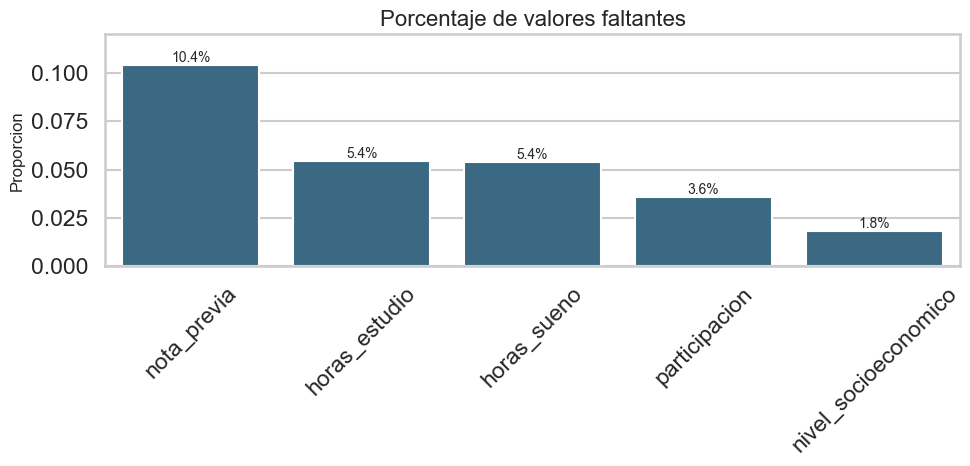

In [5]:

graficar_valores_faltantes(faltantes_tabla, CARPETA_FIGURAS_PUNTO_1 / 'missing_values.png')
plt.show()


### Lectura del grafico

Los faltantes se concentran sobre todo en `nota_previa`, y despues aparecen en `horas_estudio` y `horas_sueno`. No parece necesario eliminar columnas completas; alcanza con imputar con cuidado las features numericas afectadas.


### Grafico 2 - Distribuciones globales de features numericas

Despues de mirar faltantes, reviso la forma de las features numericas para entender sus escalas, concentraciones y posibles asimetrias antes de aplicar estandarizacion y modelos lineales.


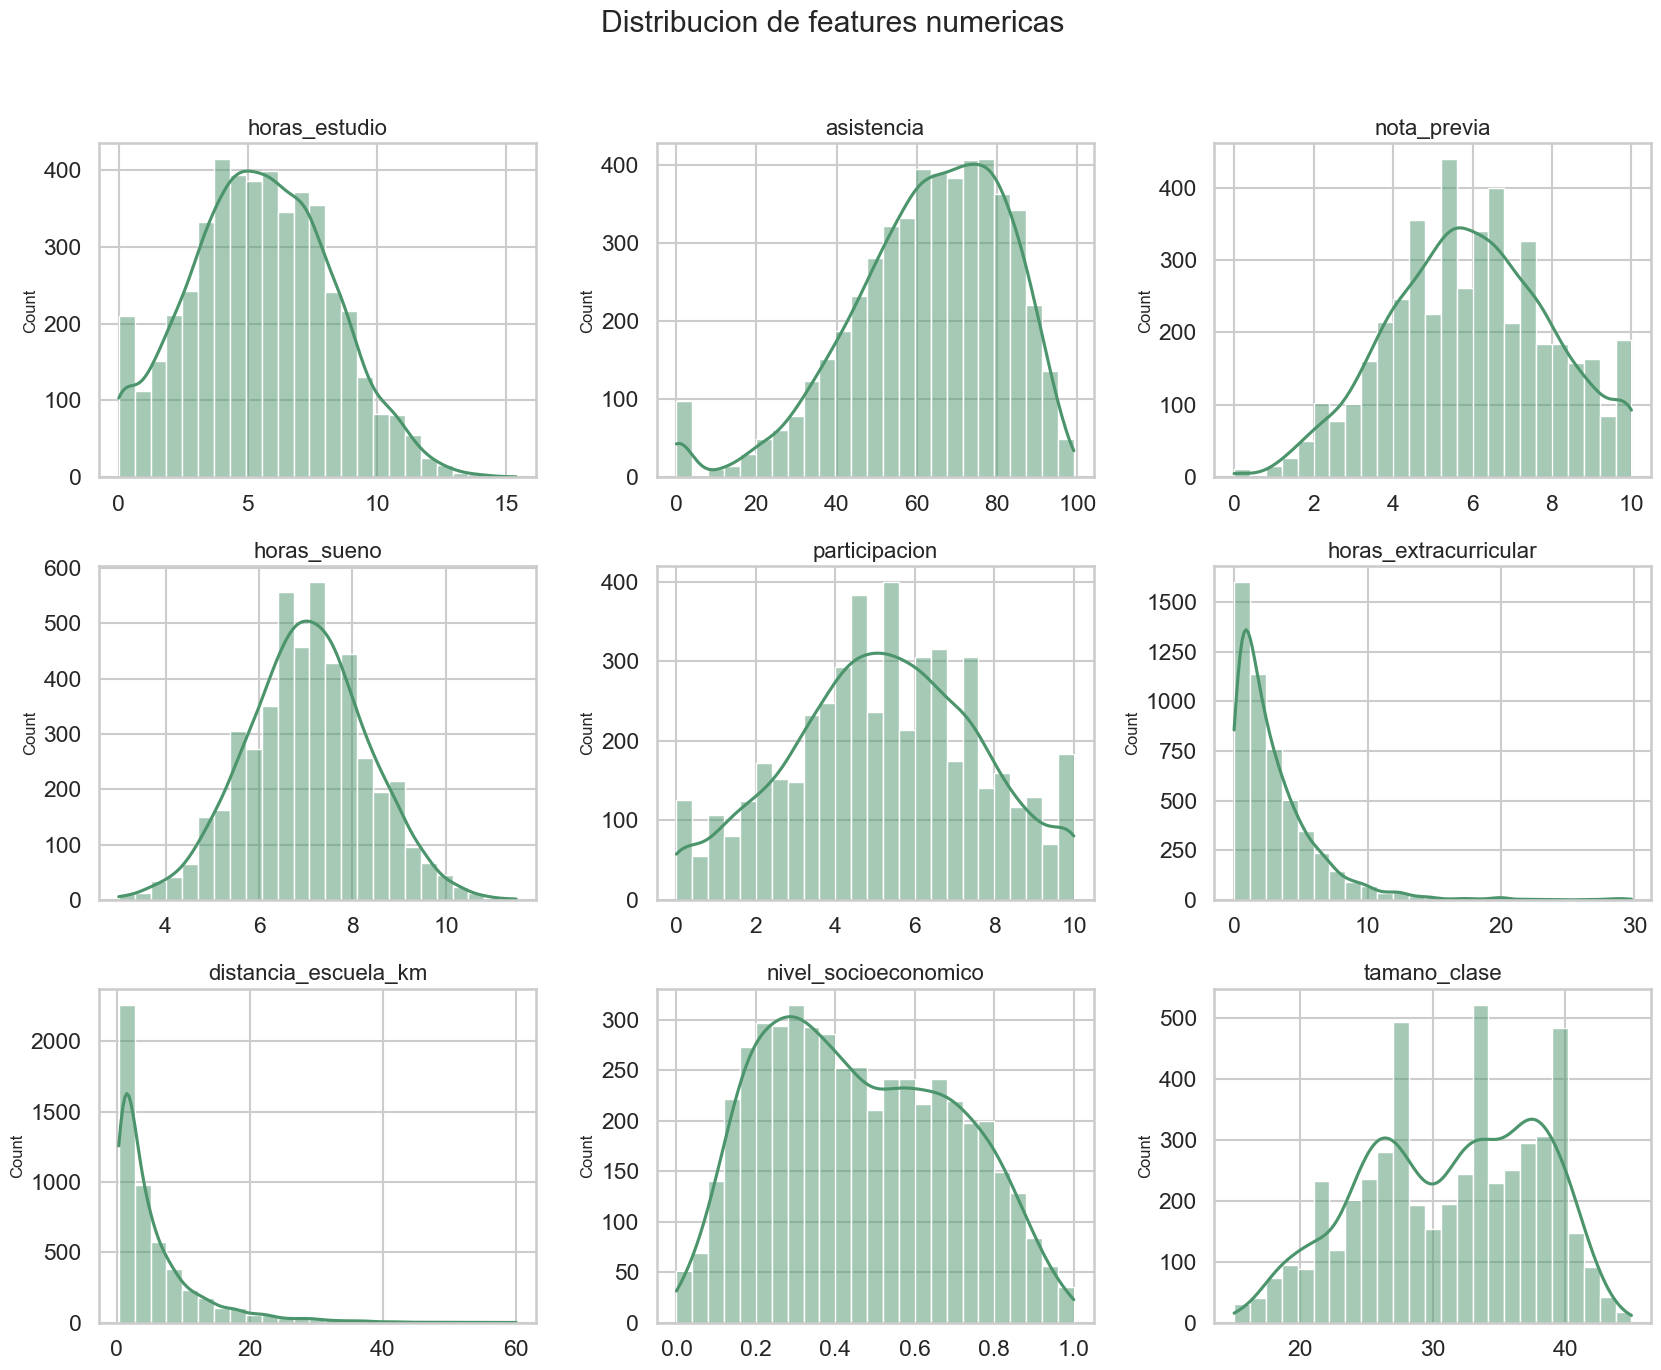

In [6]:

graficar_distribuciones_numericas(desarrollo, ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'numeric_distributions.png')
plt.show()


### Lectura del grafico

Las features tienen escalas y formas bastante distintas. `horas_sueno` esta concentrada, mientras que `distancia_escuela_km` y `horas_extracurricular` tienen colas mas largas. Esto justifica estandarizar antes de entrenar los modelos sensibles a magnitudes.


### Grafico 3 - Distribucion del objetivo

Antes de pasar a los modelos, miro como se distribuye `rendimiento` en su version multiclase y en su version binaria, porque esa distribucion define la dificultad de las metricas.


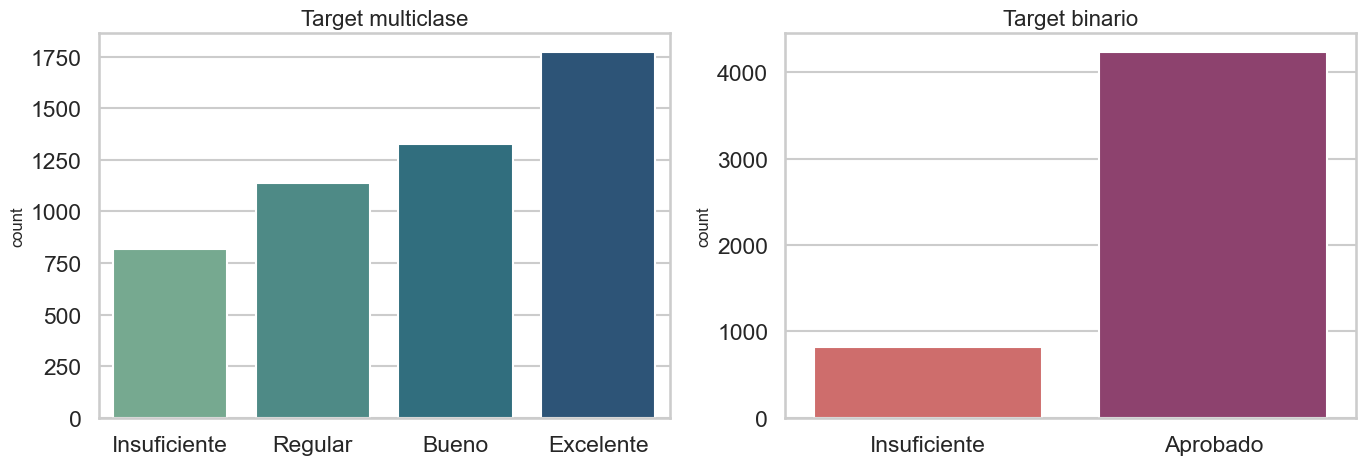

In [7]:

graficar_distribuciones_objetivo(desarrollo, ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'target_distributions.png')
plt.show()


### Lectura del grafico

El target binario esta desbalanceado: `Aprobado` domina sobre `Insuficiente`. En multiclase tambien hay mas peso en los niveles altos. Mas adelante, entonces, no alcanza con mirar `accuracy`; tambien uso `F1`, `ROC-AUC`, `PR-AUC` y rebalancing.


### Lectura del punto 1.1

El EDA deja tres alertas: faltantes en pocas features, desbalance del target y algunos outliers esperables en features como `distancia_escuela_km`. Ademas, `nota_previa` necesita una revision aparte porque aparecen valores fuera de escala.


## Punto 1.2 - Estructura por escuela del conjunto de datos

Despues del EDA global miro la base por escuelas. Quiero ver si escuela y semestre cambian la distribucion de las features o del target, porque eso despues afecta como conviene validar los modelos.


In [8]:
resumen_escuelas_tabla = resumir_features_por_escuela(desarrollo)
correlaciones_escuela_tabla = correlaciones_feature_target_por_escuela(desarrollo)
rangos_correlacion_tabla = resumir_rango_correlaciones(correlaciones_escuela_tabla)
tasa_aprobacion_tabla = tasa_aprobacion_por_escuela_semestre(desarrollo)


### Grafico 4 - Boxplots por escuela para cada feature numerica

Uso este grafico para comparar las features numericas entre escuelas. Me interesa ver si las diferencias aparecen en el centro de la distribucion, en la dispersion o en ambas.


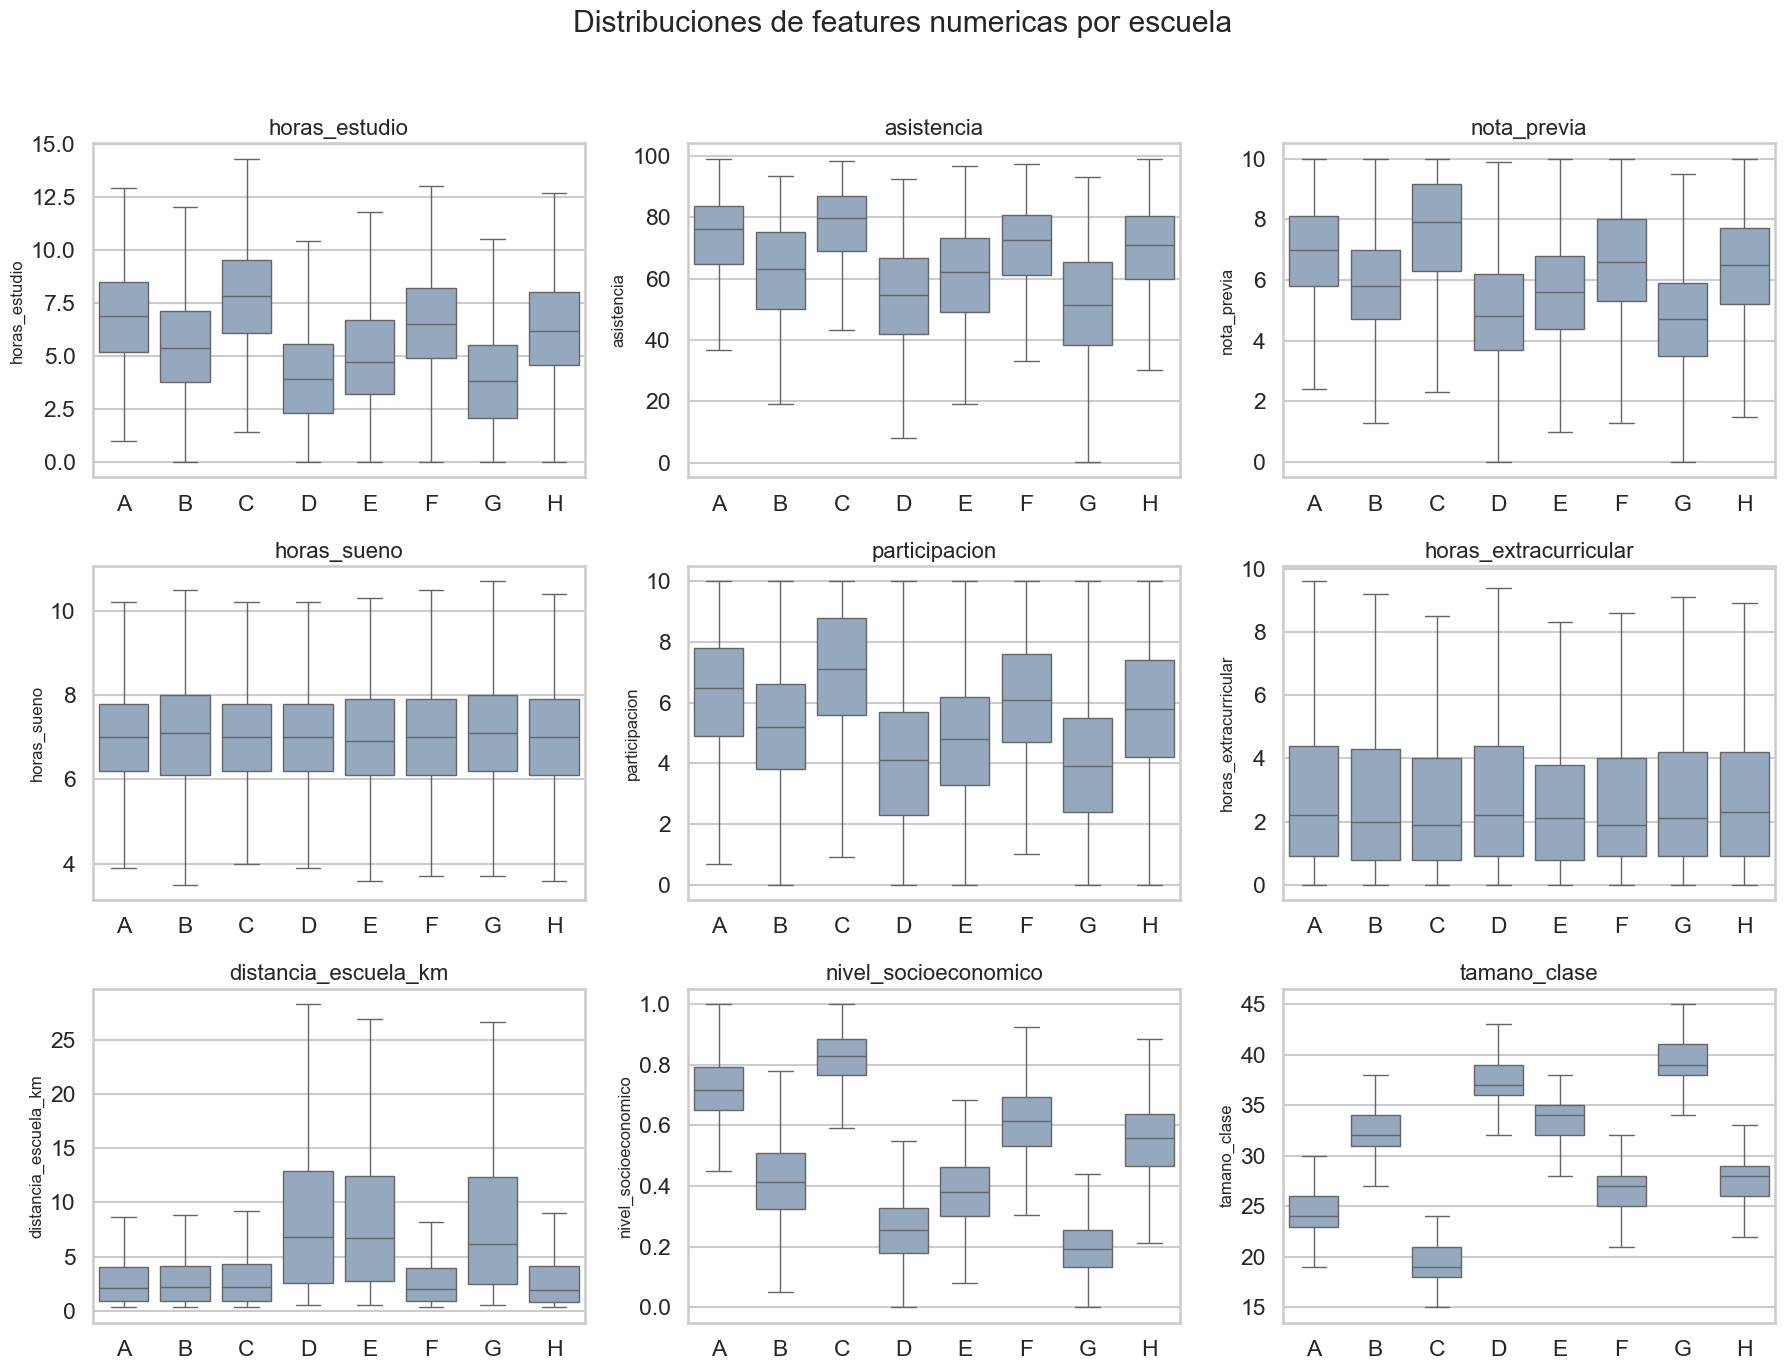

In [9]:

graficar_boxplots_numericos_por_escuela(desarrollo, ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'school_numeric_boxplots.png')
plt.show()


### Lectura del grafico

Las cajas no se superponen igual en todas las features. En algunas, las diferencias entre escuelas son claras; en otras, hay mucho mas solapamiento. Esto anticipa que algunas features van a ser mas estables que otras.


### Grafico 5 - Distribucion del objetivo por escuela

Despues de comparar features, miro si el rendimiento tambien cambia entre escuelas. Esto sirve para ver si `escuela` esta relacionado con la dificultad del problema.


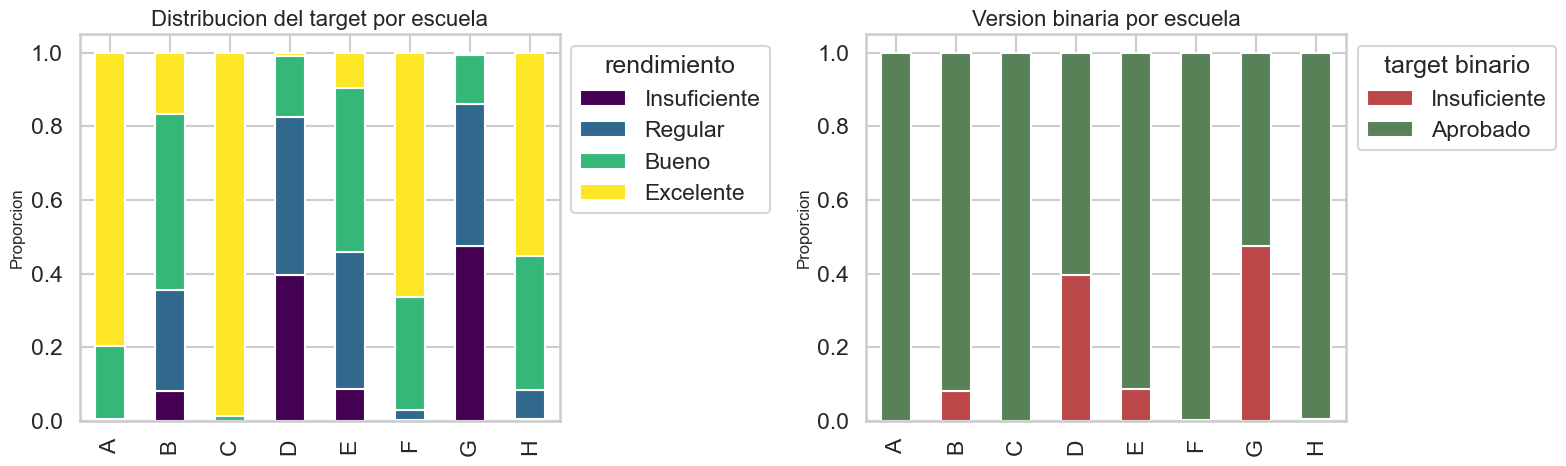

In [10]:

graficar_distribucion_objetivo_por_escuela(desarrollo, ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'target_by_school.png')
plt.show()


### Lectura del grafico

La proporcion de clases cambia entre escuelas. Algunas casi no tienen `Insuficiente`, mientras que otras concentran mas casos de riesgo. Esto ya sugiere que un Random split puede ser optimista.


### Grafico 6 - Distribucion del objetivo por semestre

Este grafico mira la otra estructura importante del dataset: el tiempo. Lo uso para ver si la distribucion de clases cambia entre semestres.


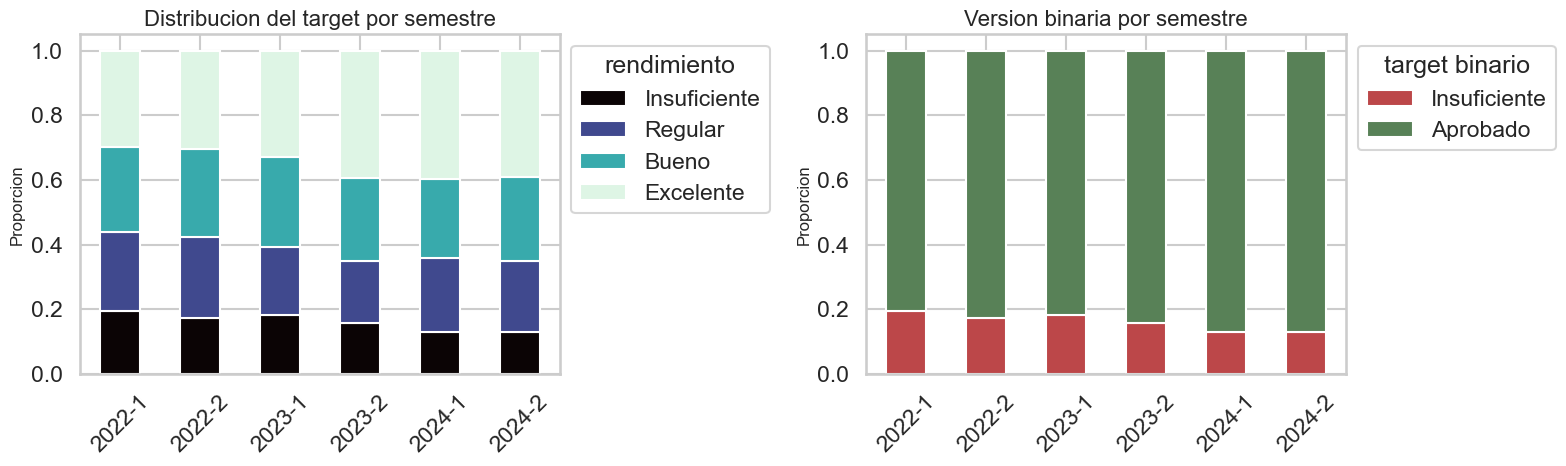

In [11]:

graficar_distribucion_objetivo_por_semestre(desarrollo, ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'target_by_semester.png')
plt.show()


### Lectura del grafico

Entre semestres hay variacion, aunque no parece tan marcada como la diferencia entre escuelas. El tiempo importa, pero la heterogeneidad institucional sigue pareciendo el eje mas fuerte del problema.


### Grafico 7 - Heatmap de aprobacion por escuela y semestre

Uso el heatmap para cruzar escuela y semestre en una sola vista. Asi se ven rapido escuelas con tasas altas o bajas de aprobacion y cambios puntuales en algun semestre.


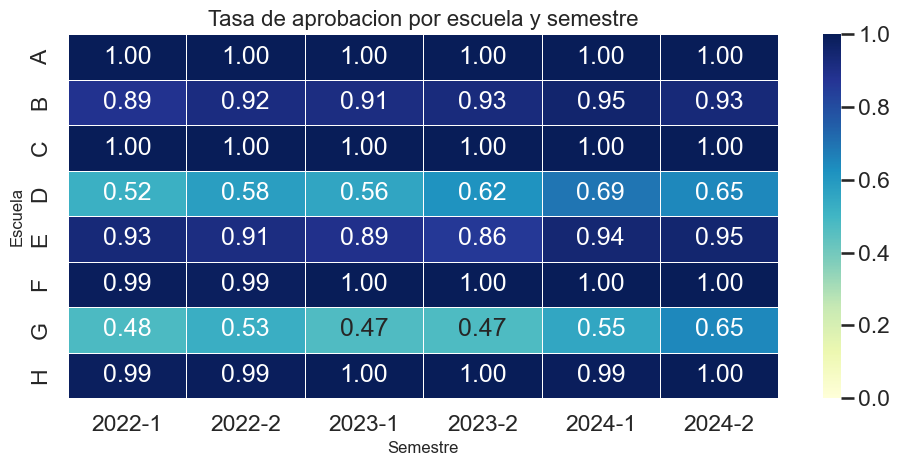

In [12]:

graficar_heatmap_tasa_aprobacion(tasa_aprobacion_tabla, ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'approval_heatmap.png')
plt.show()


### Lectura del grafico

La tasa de aprobacion no es pareja entre escuelas ni completamente estable en el tiempo. Hay escuelas mejor posicionadas y otras mas exigidas, lo que refuerza la idea de usar Group split.


### Grafico 8 - Correlacion feature-target por escuela

Este grafico no mira niveles, sino relaciones. Lo uso para ver si una misma feature se asocia con el rendimiento de manera parecida en todas las escuelas.


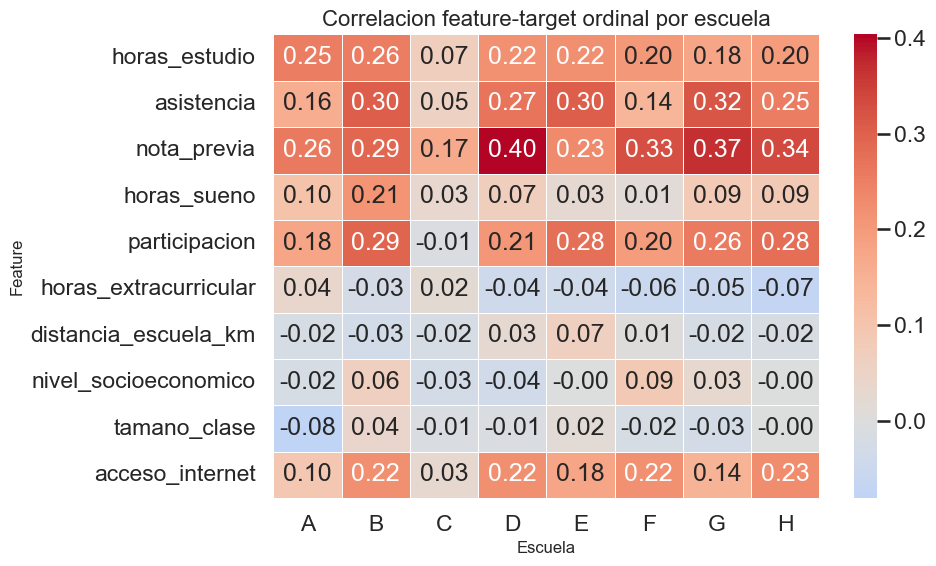

In [13]:

graficar_heatmap_correlacion_feature_objetivo(
    correlaciones_escuela_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'feature_target_correlation_heatmap.png',
)
plt.show()


### Lectura del grafico

Las correlaciones cambian entre escuelas. Algunas features mantienen una relacion parecida con el rendimiento, pero otras cambian de magnitud e incluso de signo. Esto anticipa que la estabilidad de coeficientes puede depender del validation scheme.


### Lectura del punto 1.2

Las escuelas no parecen intercambiables. Cambian features como `tamano_clase`, `asistencia`, `horas_estudio` y `nivel_socioeconomico`, y tambien cambia la proporcion de `Insuficiente`. Por eso despues uso splits que respetan esa estructura.


## Punto 1.3 - Limpieza y preprocesamiento

Con el EDA armado, defino una limpieza que corrija errores claros sin meter informacion del validation set dentro del entrenamiento.


### Como trabajo el caso de imputacion de la `nota_previa`

**Por que abro este bloque**

`nota_previa > 10` aparece como error de dominio. Antes de mandarlo directo a `NaN`, pruebo una hipotesis mas simple: que esas observaciones sean la misma nota cargada en escala `0-100`.


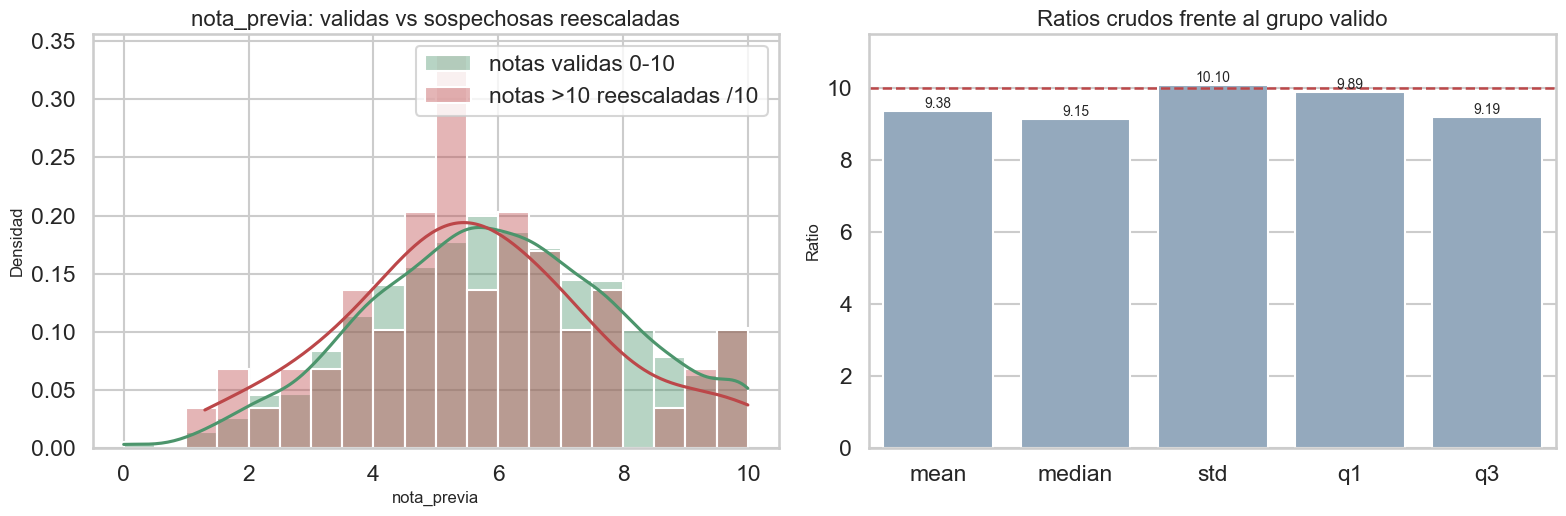

In [14]:
auditoria_nota_previa = preparar_auditoria_nota_previa(desarrollo_crudo, prueba_crudo)

resumen_escala_nota_previa_tabla = auditoria_nota_previa['resumen_escala_df']
metricas_escala_nota_previa_tabla = auditoria_nota_previa['metricas_escala_df']
impacto_reescalado_nota_previa_tabla = auditoria_nota_previa['impacto_reescalado_df']
patron_formato_nota_previa_tabla = auditoria_nota_previa['patron_formato_df']

graficar_auditoria_escala_nota_previa(
    desarrollo_crudo,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'nota_previa_scale_audit.png',
)
plt.show()


### Lectura del chequeo de escala en `nota_previa`

Una parte de `nota_previa` parece estar en escala `0-100`. Como al dividir por 10 queda alineada con el resto, reescale esos casos antes de marcar faltantes. Solo deje en `NaN` los valores que siguieron fuera de rango.


### Grafico 9 - Medianas por escuela para justificar la imputacion

Antes de imputar, comparo la mediana de cada escuela contra la mediana global en las features con faltantes. Si las escuelas tienen centros distintos, una imputacion global puede tapar diferencias reales.


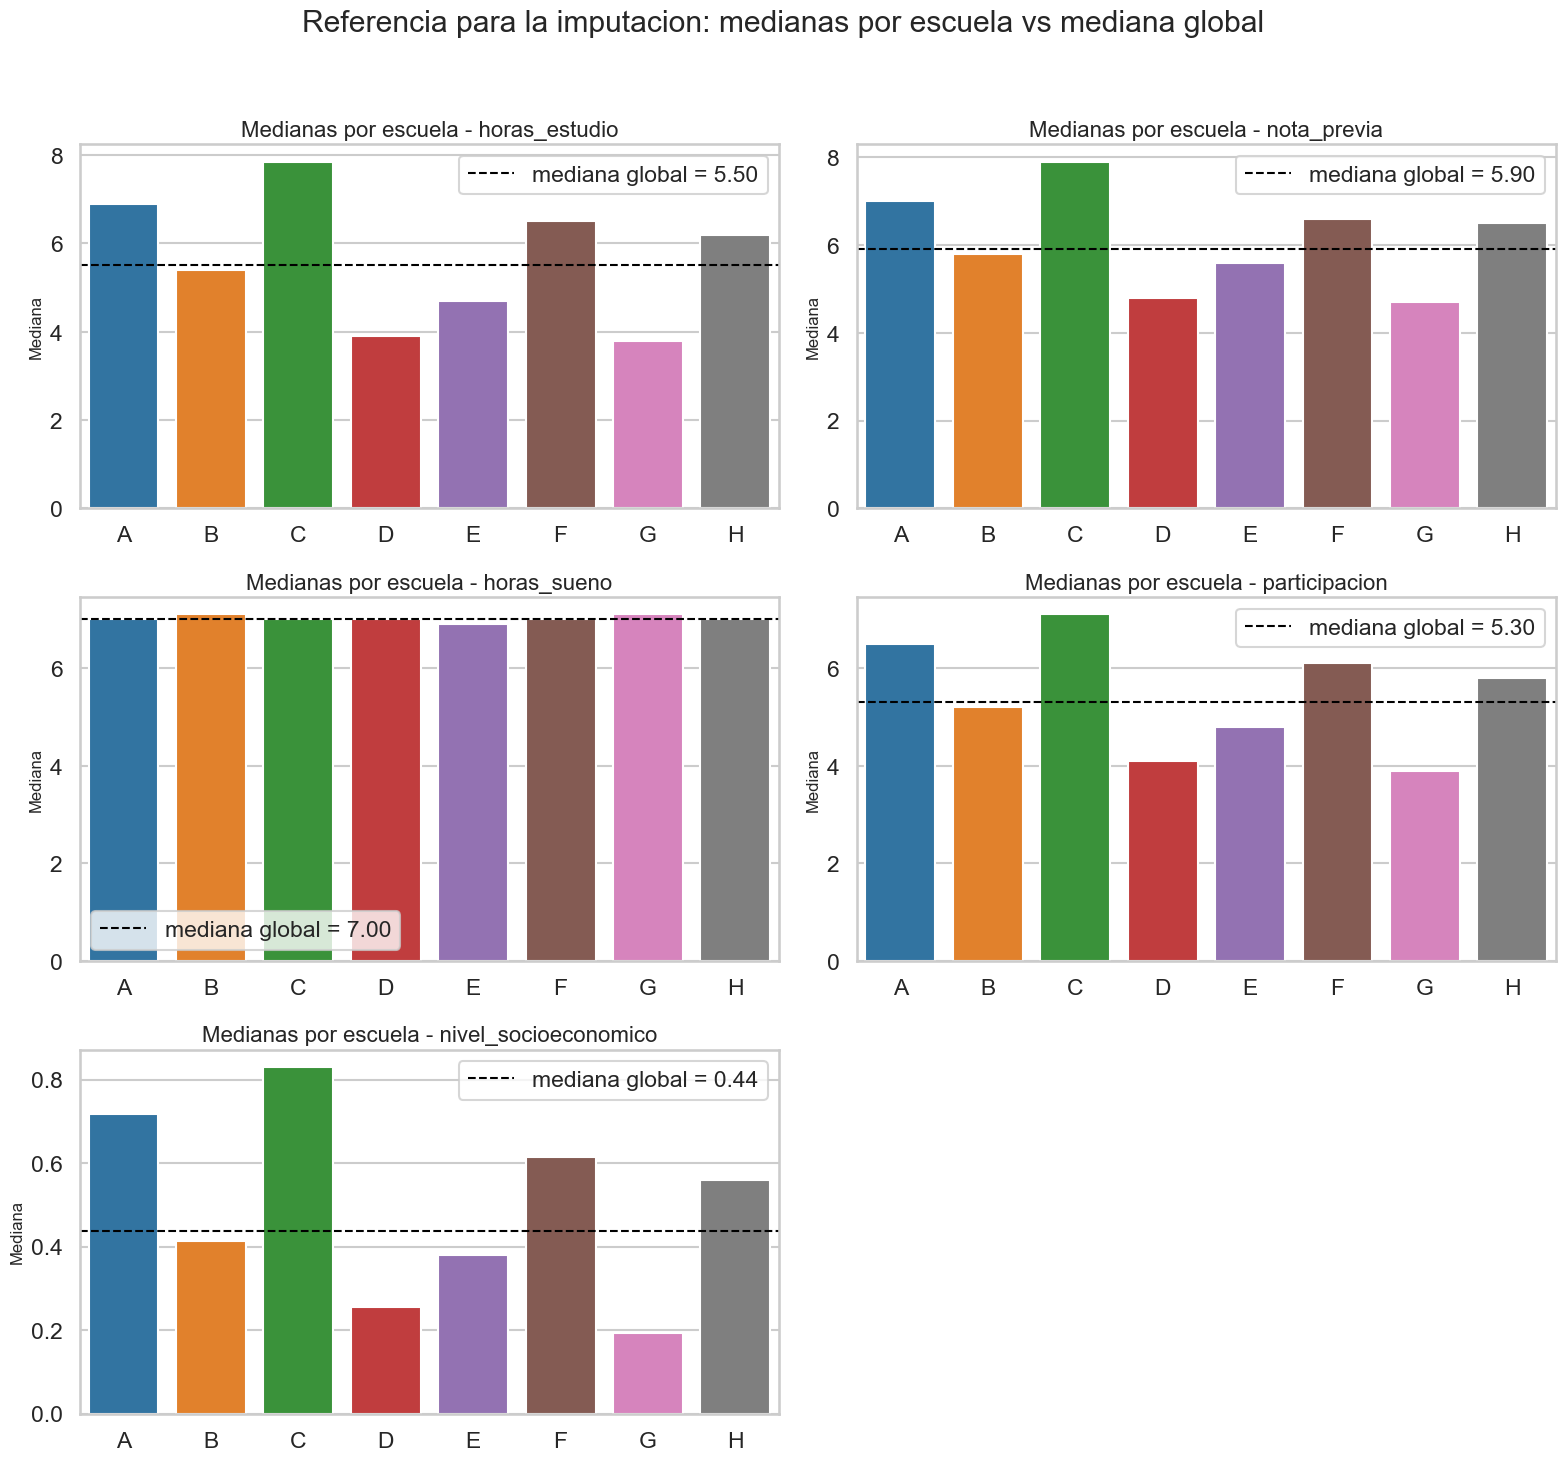

In [15]:

graficar_medianas_imputacion_por_escuela(
    desarrollo,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_1 / 'imputation_medians_by_school.png',
)
plt.show()


### Lectura del grafico

Las medianas no son iguales entre escuelas. En varias features, una sola mediana global mezclaria contextos distintos. Por eso imputo con mediana por escuela, ajustada solo con el entrenamiento de cada fold para evitar leakage.


In [16]:
faltantes_post_imputacion_dev = desarrollo_modelo_base.isna().sum().rename('n_missing_post_imputation').to_frame()
faltantes_post_imputacion_test = prueba_modelo_base.isna().sum().rename('n_missing_post_imputation').to_frame()


### Decisiones de preprocesamiento adoptadas

- `escuela` pasa a mayuscula para no duplicar escuelas.
- Si `nota_previa` esta entre `10` y `100`, la reescale dividiendo por `10`.
- Solo dejo en `NaN` los valores que siguen fuera de rango despues de ese ajuste.
- La imputacion numerica se hace con mediana por escuela y siempre dentro del fold correspondiente.


## Punto 2 - Clasificacion binaria y estrategias de splitting

Uso la version binaria del objetivo (`rendimiento_binario_num`) y una regresion logistica L2. No quiero medir solo si el modelo funciona; tambien quiero ver cuanto cambia la conclusion segun el split.


En este punto comparo `Random split`, `Group split` y `Temporal split`, y despues reviso la estabilidad de los coeficientes con distintos cross-validation schemes.


### Como esta armado el flujo de modelado

En cada fold repito la misma secuencia: imputacion por escuela, estandarizacion, dummies para categoricas y entrenamiento de la logistica. La parte mecanica esta en `src/` para que el notebook quede enfocado en resultados.


In [17]:
preparacion_punto2 = preparar_punto2(desarrollo)

grilla_lambda = preparacion_punto2['grilla_lambda']
parametros_modelo = preparacion_punto2['parametros_modelo']
columna_target = preparacion_punto2['columna_target']
train_random = preparacion_punto2['train_random']
validation_random = preparacion_punto2['validation_random']
holdout_schools = preparacion_punto2['holdout_schools']
train_group = preparacion_punto2['train_group']
validation_group = preparacion_punto2['validation_group']
train_temporal = preparacion_punto2['train_temporal']
validation_temporal = preparacion_punto2['validation_temporal']
temporal_validation_semester = preparacion_punto2['temporal_validation_semester']


### Ajuste de `lambda`

Antes de comparar resultados finales, ajusto `lambda` por estrategia. Uso `F1` porque me interesa equilibrar `precision` y `recall`, no solo acertar mucho en promedio.


In [18]:
resultados_punto2 = correr_punto2_binario(desarrollo, preparacion_punto2)

ajuste_random_tabla = resultados_punto2['ajuste_random_df']
ajuste_group_tabla = resultados_punto2['ajuste_group_df']
ajuste_temporal_tabla = resultados_punto2['ajuste_temporal_df']
mejores_lambda_tabla = resultados_punto2['mejores_lambda_df']
metricas_estrategias_tabla = resultados_punto2['metricas_estrategias_df']
evaluacion_random = resultados_punto2['evaluacion_random']
evaluacion_group = resultados_punto2['evaluacion_group']
evaluacion_temporal = resultados_punto2['evaluacion_temporal']
matriz_confusion_random_tabla = resultados_punto2['matriz_confusion_random_df']
matriz_confusion_group_tabla = resultados_punto2['matriz_confusion_group_df']
matriz_confusion_temporal_tabla = resultados_punto2['matriz_confusion_temporal_df']
tasa_positiva_random = resultados_punto2['tasa_positiva_random']
tasa_positiva_group = resultados_punto2['tasa_positiva_group']
tasa_positiva_temporal = resultados_punto2['tasa_positiva_temporal']
distribucion_coeficientes_tabla = resultados_punto2['distribucion_coeficientes_df']
estabilidad_coeficientes_tabla = resultados_punto2['estabilidad_coeficientes_df']
features_inestables = resultados_punto2['features_inestables']


### Grafico 10 - Validation F1 vs `lambda` en panel 2x2


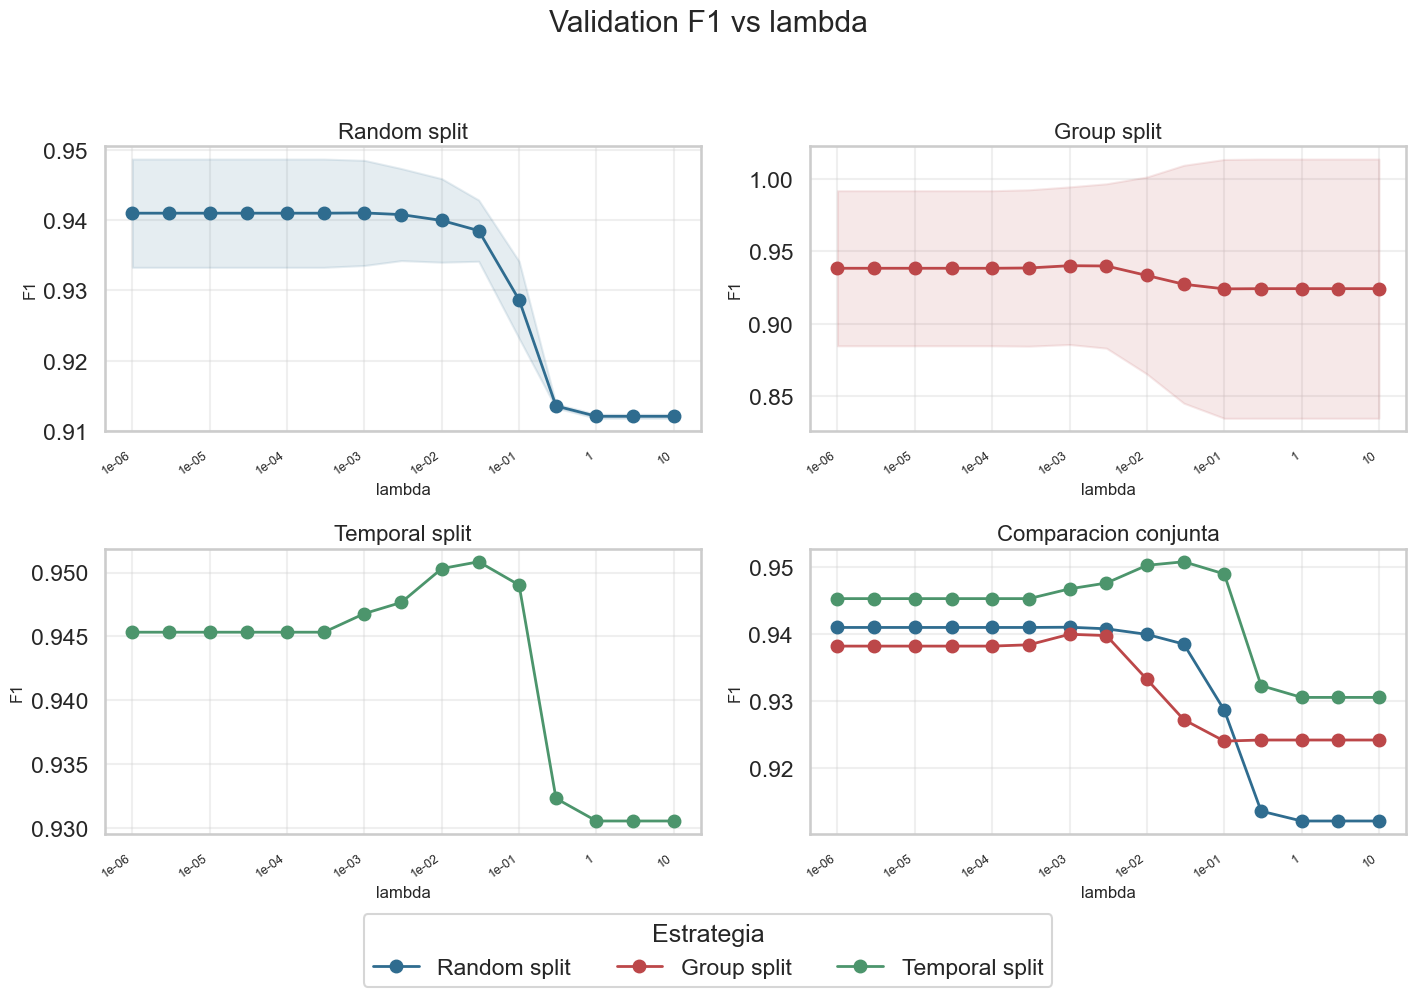

In [19]:
graficar_panel_ajuste_lambda(
    [
        {'df': ajuste_random_tabla, 'label': 'Random split', 'use_mean_columns': True},
        {'df': ajuste_group_tabla, 'label': 'Group split', 'use_mean_columns': True},
        {'df': ajuste_temporal_tabla, 'label': 'Temporal split', 'use_mean_columns': False},
    ],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'lambda_tuning_panel.png',
)
plt.show()


### Lectura del grafico

La curva de `Random split` tiene una zona buena amplia. En `Group split`, el rendimiento baja y depende mas de `lambda`, senal de que generalizar a escuelas nuevas cuesta mas. El Temporal split queda en el medio.


### Evaluacion final de las tres estrategias

Con `lambda` ya elegido, ahora comparo las metricas finales de cada esquema manteniendo `Aprobado = 1` como clase positiva.


In [20]:
display(
    metricas_estrategias_tabla.rename(
        columns={
            'strategy': 'estrategia',
            'best_lambda': 'mejor_lambda',
        }
    ).round(4)
)


,estrategia,mejor_lambda,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Random split,0.001,0.8923,0.9074,0.9705,0.9379,0.9383,0.9880
1,Group split,0.001,0.8553,0.8734,0.9507,0.9104,0.9164,0.9756
2,Temporal split,0.030,0.9138,0.9439,0.9579,0.9508,0.9536,0.9929


### Grafico 11 - Comparacion global de metricas

Este resumen sirve para comparar de una sola mirada `accuracy`, `precision`, `recall`, `F1`, `ROC-AUC` y `PR-AUC` entre los tres esquemas de splitting.


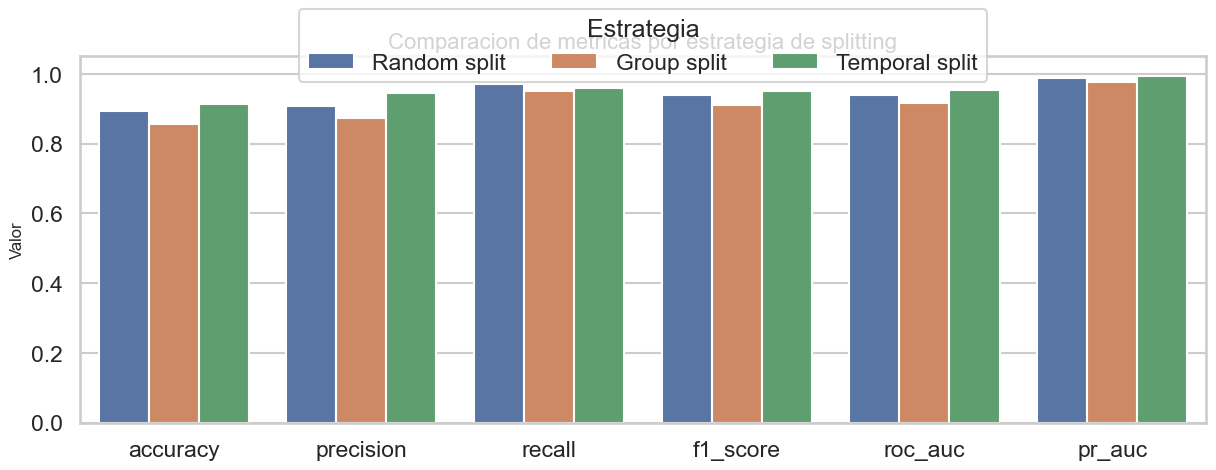

In [21]:
graficar_comparacion_metricas_estrategias(
    metricas_estrategias_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'strategy_metric_comparison.png',
)
plt.show()


### Lectura del grafico

`Random split` sale mejor en casi todas las metricas, pero tambien es la evaluacion mas optimista porque mezcla escuelas. `Group split` cae mas, sobre todo en la clase dificil. El Temporal split queda entre ambos.


### Grafico 12 - Matrices de confusion lado a lado


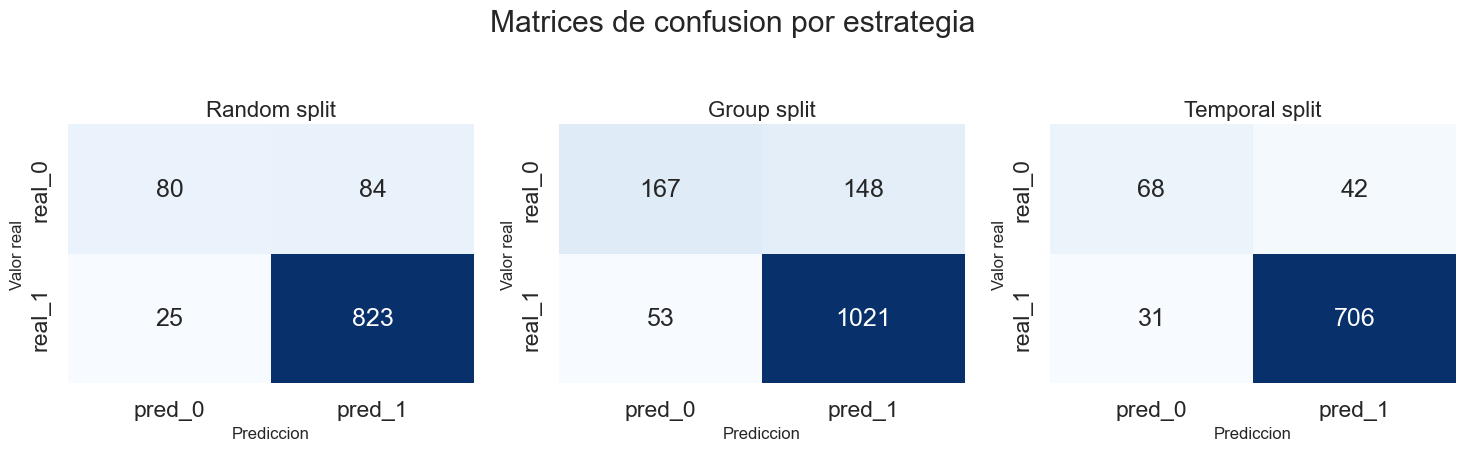

In [22]:
graficar_triplete_matriz_confusion(
    [
        {'df': matriz_confusion_random_tabla, 'label': 'Random split'},
        {'df': matriz_confusion_group_tabla, 'label': 'Group split'},
        {'df': matriz_confusion_temporal_tabla, 'label': 'Temporal split'},
    ],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'confusion_matrix_triptych.png',
)
plt.show()


### Lectura del grafico

Las matrices muestran que no solo cambia la metrica final, sino el tipo de error. En el Group split aparecen mas problemas con `Insuficiente`, justo la clase que mas interesa detectar. El desbalance tambien empuja al modelo hacia `Aprobado`.


### Grafico 13 - Curvas ROC en panel 2x2


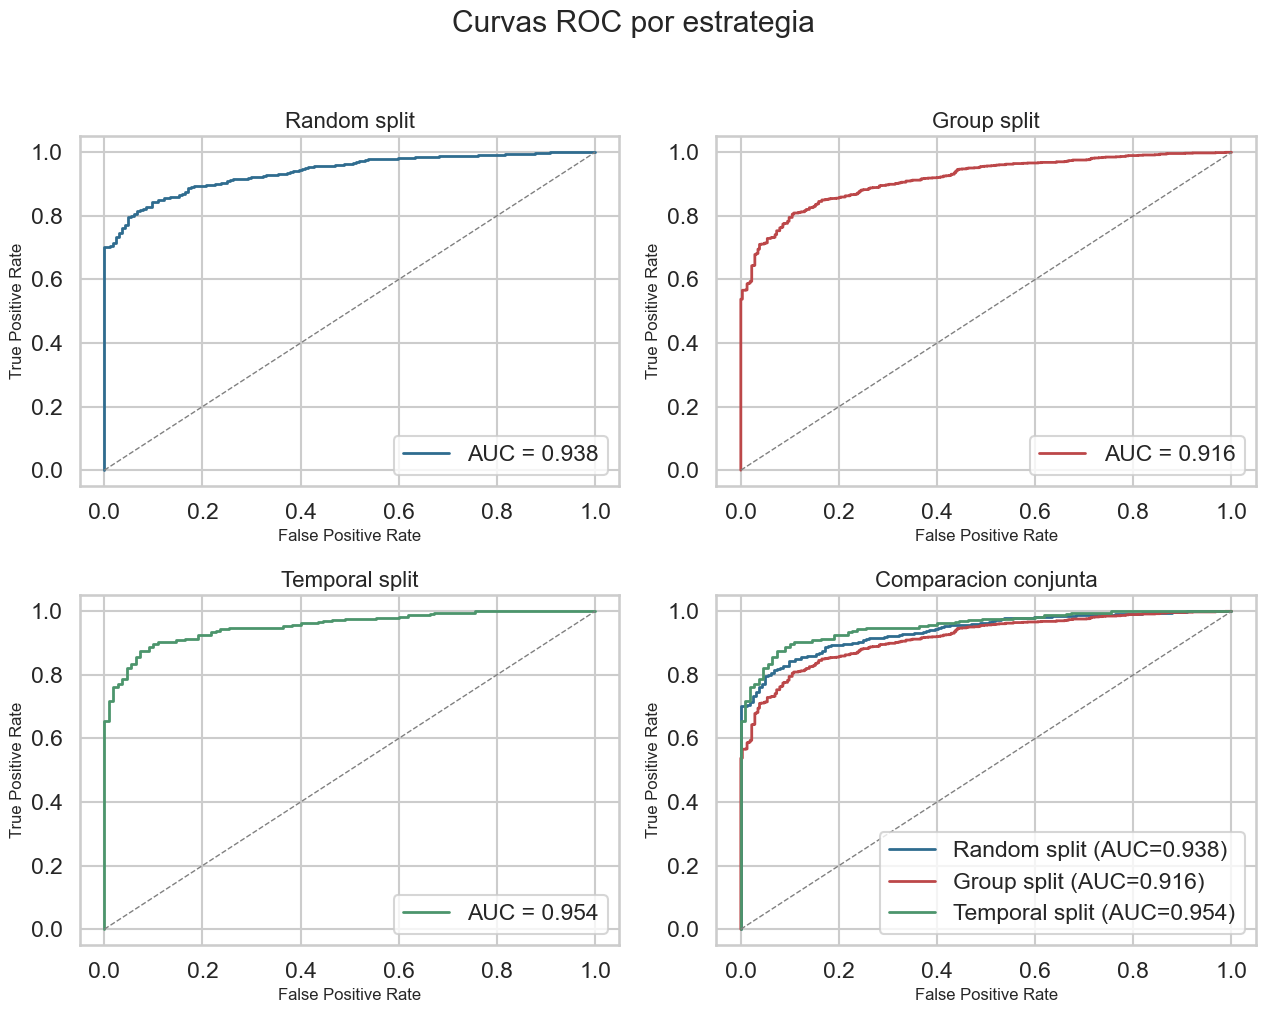

In [23]:
graficar_panel_curva_roc(
    [
        {'df': evaluacion_random['roc_curve'], 'auc': evaluacion_random['metrics']['roc_auc'], 'label': 'Random split'},
        {'df': evaluacion_group['roc_curve'], 'auc': evaluacion_group['metrics']['roc_auc'], 'label': 'Group split'},
        {'df': evaluacion_temporal['roc_curve'], 'auc': evaluacion_temporal['metrics']['roc_auc'], 'label': 'Temporal split'},
    ],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'roc_curve_panel.png',
)
plt.show()


### Lectura del grafico

Las tres ROC estan por encima de la diagonal, pero con distinta separacion. El Random split separa mejor, el Group split pierde margen y el temporal queda intermedio. La diferencia apunta otra vez a la heterogeneidad entre escuelas.


### Grafico 14 - Curvas Precision-Recall en panel 2x2

Como el problema esta desbalanceado, conviene mirar `precision` y `recall` con mas detalle. Por eso repetimos la misma logica: tres curvas separadas y una comparacion conjunta.


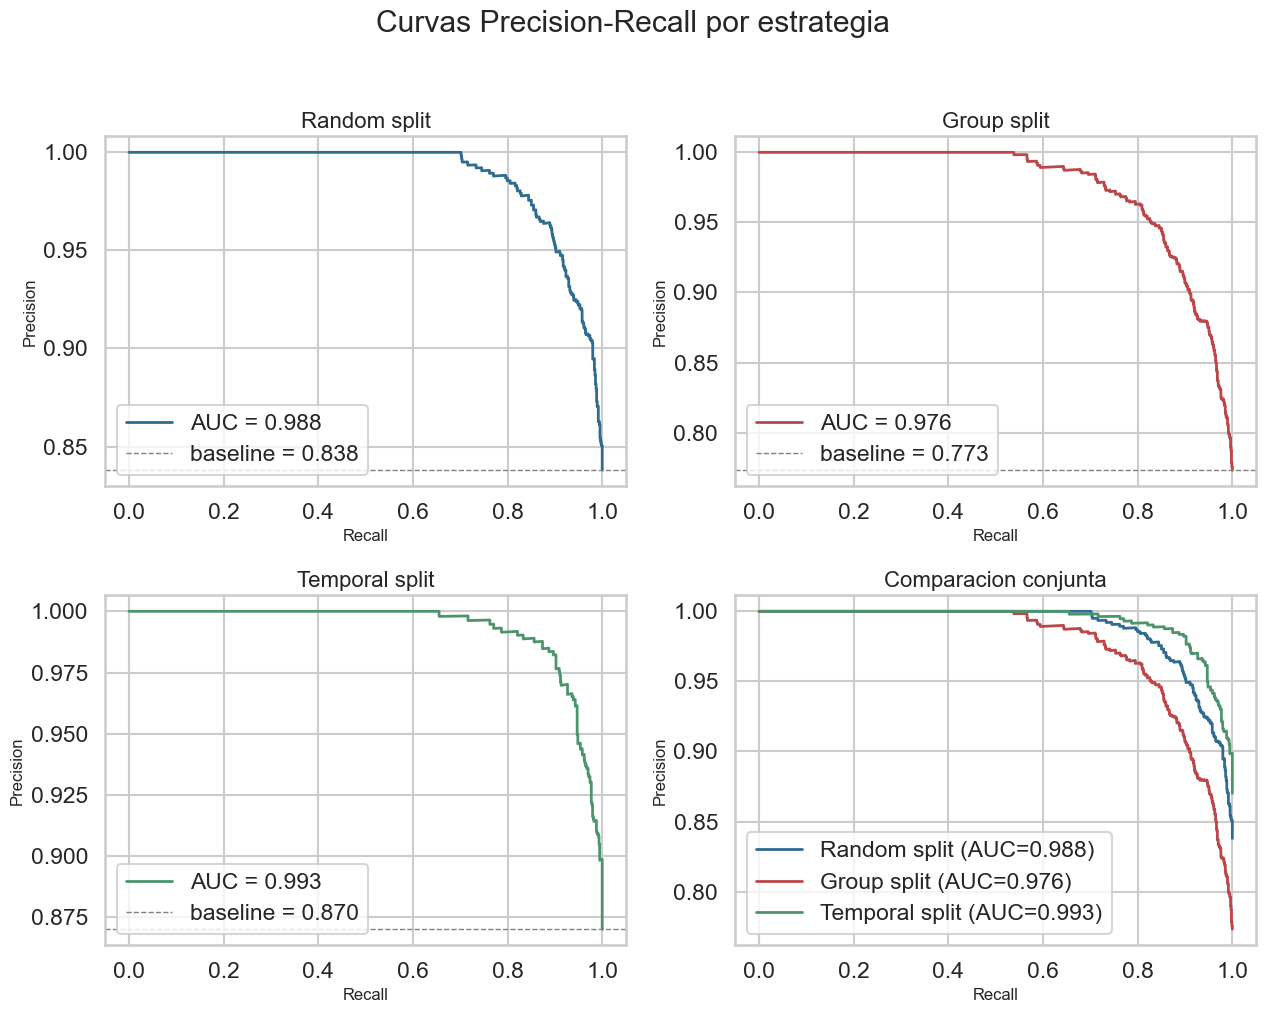

In [24]:
graficar_panel_curva_precision_recall(
    [
        {'df': evaluacion_random['pr_curve'], 'auc': evaluacion_random['metrics']['pr_auc'], 'baseline': tasa_positiva_random, 'label': 'Random split'},
        {'df': evaluacion_group['pr_curve'], 'auc': evaluacion_group['metrics']['pr_auc'], 'baseline': tasa_positiva_group, 'label': 'Group split'},
        {'df': evaluacion_temporal['pr_curve'], 'auc': evaluacion_temporal['metrics']['pr_auc'], 'baseline': tasa_positiva_temporal, 'label': 'Temporal split'},
    ],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'pr_curve_panel.png',
)
plt.show()


### Lectura del grafico

En PR se ve mejor el costo del desbalance. Para sostener mas `recall`, el Group split pierde `precision` antes que el Random split. Esto confirma que validar mezclando escuelas deja una imagen demasiado favorable.


### Lectura del inciso 2.1

El modelo funciona, pero la conclusion depende del split. Si mezclo escuelas, el resultado parece muy bueno; si valido sobre escuelas nuevas, la tarea se vuelve mas dificil.


### Estabilidad de coeficientes

Ahora paso a la parte 2.3. La idea es ver si los coeficientes se mantienen parecidos cuando cambian los folds o si dependen demasiado de que escuelas quedaron en entrenamiento.


La estabilidad de coeficientes queda resumida en dos vistas: la distribucion fold a fold de las features mas sensibles y la comparacion directa de desvios entre `Random KFold` y `GroupKFold`.


### Grafico 15 - Distribucion de coeficientes para las features mas inestables

La tabla de desvio estandar resume el problema, pero esta figura deja ver la distribucion fold a fold de los coeficientes mas sensibles.


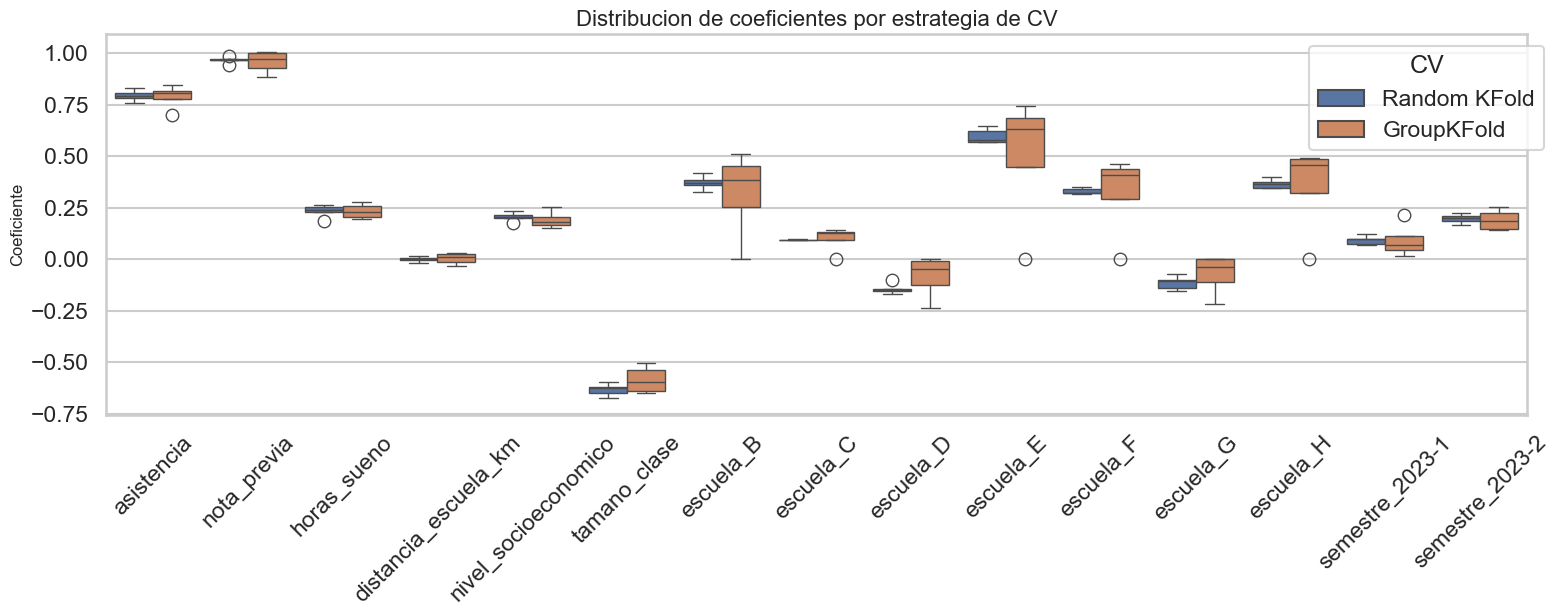

In [25]:
graficar_distribuciones_coeficientes(
    distribucion_coeficientes_tabla,
    features_inestables,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'coefficient_distributions_top_features.png',
)
plt.show()


### Lectura del grafico

Las cajas muestran cuanto cambian los coeficientes entre folds. Cuando `GroupKFold` tiene cajas mas abiertas, el peso de esa feature depende de que escuelas quedaron en entrenamiento. No conviene leer esos coeficientes como totalmente estables.


### Grafico 16 - Comparacion de desvio estandar en las 15 features mas inestables

Aca comparo, para cada feature, el desvio estandar en `Random KFold` y en `GroupKFold`. Es una forma mas directa de ver que coeficientes se vuelven inestables.


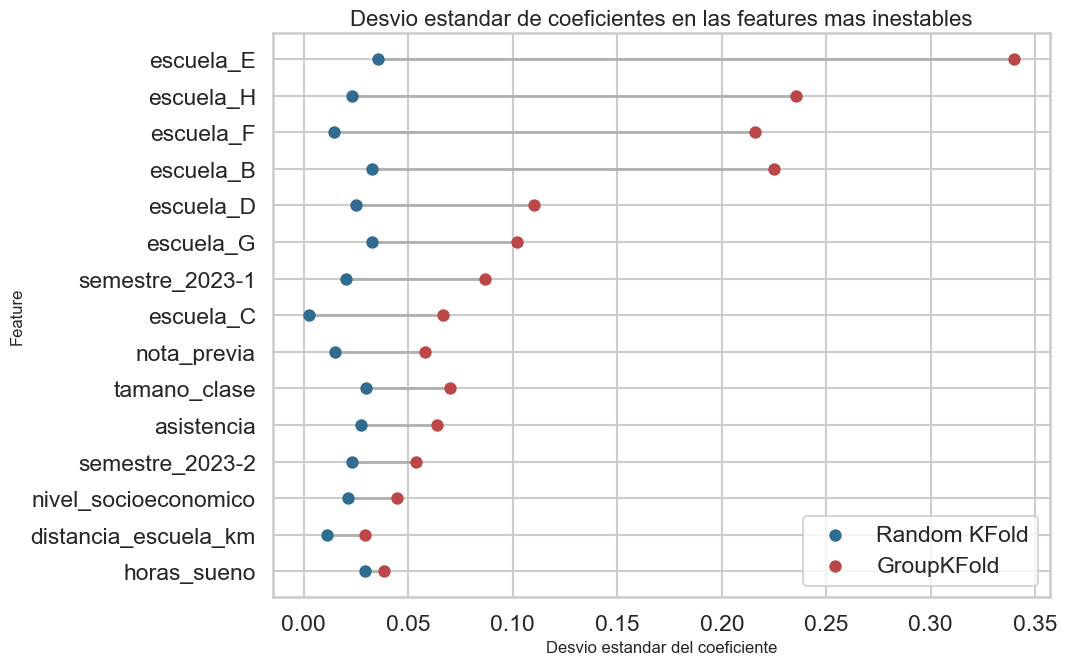

In [26]:
graficar_comparacion_std_coeficientes(
    estabilidad_coeficientes_tabla,
    cantidad_principales=15,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_2 / 'coefficient_std_comparison.png',
)
plt.show()


### Lectura del grafico

Las features en las que el desvio con GroupKFold se despega son las mas sensibles a la composicion de escuelas. Esa diferencia importa si se quiere interpretar el signo o la magnitud del coeficiente.


### Conclusion del punto 2

La logistica binaria rinde bien, pero depende mucho del validation scheme. El Random split es optimista, el Group split es el escenario mas duro y el temporal funciona como referencia intermedia.


## Punto 3 - Clasificacion multiclase y ensemble learning

En esta seccion trabajo con la version multiclase del objetivo y uso `GroupKFold` por escuela, tal como pide la consigna. Comparo `LDA`, logistica multiclase y `Random Forest` bajo el mismo esquema de evaluacion.


En este punto primero defino los folds por escuela, despues ajusto los hiperparametros y finalmente comparo los tres modelos con metricas globales, metricas one-vs-all y curvas por clase.


### Como se evalua esta parte

Uso out-of-fold predictions con `GroupKFold` por escuela. Para elegir hiperparametros priorizo `macro F1`, porque no quiero que la clase mas frecuente tape el rendimiento en las demas.


In [27]:
preparacion_punto3 = preparar_punto3(desarrollo, n_folds=4)
folds_group_multiclase = preparacion_punto3['folds_group_multiclase']


### Como funcionan los modelos del punto 3

Los tres modelos usan el mismo preprocesamiento y los mismos folds, pero aprenden de formas distintas. Dejo las formulas principales para que se entienda que estima cada uno.


#### `LDA` con covarianza compartida

En `LDA` estimo una media por clase, una probabilidad a priori por clase y una covarianza comun. Para cada clase `k`:

$$
\pi_k = \frac{n_k}{n}
$$

$$
\mu_k = \frac{1}{n_k}\sum_{i:y_i=k} x_i
$$

La covarianza compartida se calcula acumulando, para cada clase, los productos matriciales de las observaciones centradas:

$$
\Sigma_{sum} = \sum_{k=1}^{K} (X_k - \mu_k)^T(X_k - \mu_k)
$$

Luego normalizo por los grados de libertad y agrego un pequeno `ridge` diagonal para estabilizar la inversion:

$$
\Sigma_{ridge} = \frac{\Sigma_{sum}}{n-K} + \alpha I
$$

Con esa matriz, los pesos lineales de todas las clases quedan reunidos en:

$$
W = M\Sigma_{ridge}^{-1}
$$

donde `M` es la matriz que tiene una media de clase por fila. El intercepto de cada clase incorpora el termino cuadratico y el prior:

$$
b_k = -\frac{1}{2}w_k\mu_k^T + \log(\pi_k)
$$

Finalmente, los scores se calculan para todas las observaciones con:

$$
S = XW^T + b
$$

La clase predicha es la de mayor score.


#### Logistica multiclase con `softmax` y regularizacion `L2`

En la logistica multiclase, los parametros que se aprenden son una matriz de pesos y un vector de interceptos:

$$
W \in \mathbb{R}^{p \times K}, \quad b \in \mathbb{R}^{K}
$$

`p` es la cantidad de features ya preprocesadas y `K` la cantidad de clases. Al comenzar el entrenamiento, parto de pesos e interceptos iniciales:

$$
W^{(0)} = 0, \quad b^{(0)} = 0
$$

En cada iteracion `t`, primero calculo los scores para todas las observaciones y clases:

$$
Z^{(t)} = XW^{(t)} + b^{(t)}
$$

Despues transformo esos scores en probabilidades con `softmax`:

$$
P^{(t)} = softmax(Z^{(t)})
$$

Si `Y` es la matriz one-hot de clases reales, el error matricial es:

$$
E^{(t)} = P^{(t)} - Y
$$

Con ese error, los gradientes quedan:

$$
\nabla_W^{(t)} = \frac{X^T E^{(t)}}{n} + \lambda W^{(t)}
$$

$$
\nabla_b^{(t)} = mean(E^{(t)})
$$

Las nuevas estimaciones de los parametros se obtienen con descenso por gradiente:

$$
W^{(t+1)} = W^{(t)} - \eta\nabla_W^{(t)}
$$

$$
b^{(t+1)} = b^{(t)} - \eta\nabla_b^{(t)}
$$



#### Random Forest con arboles de entropia

En `Random Forest` el entrenamiento consiste en construir muchos arboles, y cada arbol elige cortes que separen mejor las clases.

La mezcla de clases en un nodo se mide con entropia:

$$
H(S) = -\sum_k p_k\log_2(p_k)
$$

Para un corte candidato, se calcula la entropia ponderada de los dos hijos:

$$
H_{split} = \frac{n_L}{n}H(S_L) + \frac{n_R}{n}H(S_R)
$$

La calidad del corte se mide con ganancia de informacion:

$$
Gain = H(S) - H_{split}
$$

El arbol se queda con el corte que maximiza esa ganancia, siempre respetando restricciones como profundidad maxima y minimo de muestras por hoja.

Cada arbol del bosque se entrena sobre una muestra `bootstrap`. Para predecir, el bosque promedia las probabilidades estimadas por todos los arboles:

$$
P_{forest}(y=k \mid x) = \frac{1}{T}\sum_{t=1}^{T} P_t(y=k \mid x)
$$

La clase final es la de mayor probabilidad promedio.


### Ajuste de modelos del punto 3

En `LDA` ajusto `covariance_ridge`, en la logistica multiclase ajusto `lambda` y en `Random Forest` comparo una grilla corta. Uso el mismo `GroupKFold` por escuela para que la comparacion sea justa.


In [28]:
busqueda_punto3 = ajustar_modelos_punto3(
    desarrollo,
    folds_group_multiclase,
)

ajuste_lda_tabla = busqueda_punto3['ajuste_lda_df']
ajuste_logistica_multiclase_tabla = busqueda_punto3['ajuste_logistica_multiclase_df']
ajuste_rf_tabla = busqueda_punto3['ajuste_rf_df']
mejor_config_lda = busqueda_punto3['mejor_config_lda']
mejor_config_logistica_multiclase = busqueda_punto3['mejor_config_logistica_multiclase']
mejor_config_rf = busqueda_punto3['mejor_config_rf']


### Grafico 17 - Sensibilidad numerica de `ridge` en LDA

`LDA` no usa `lambda`, pero necesita estabilizar la inversion de la covarianza compartida. Por eso miro como cambia el `macro F1` al variar el `ridge`: poco `ridge` puede ser inestable, demasiado `ridge` deforma la covarianza.


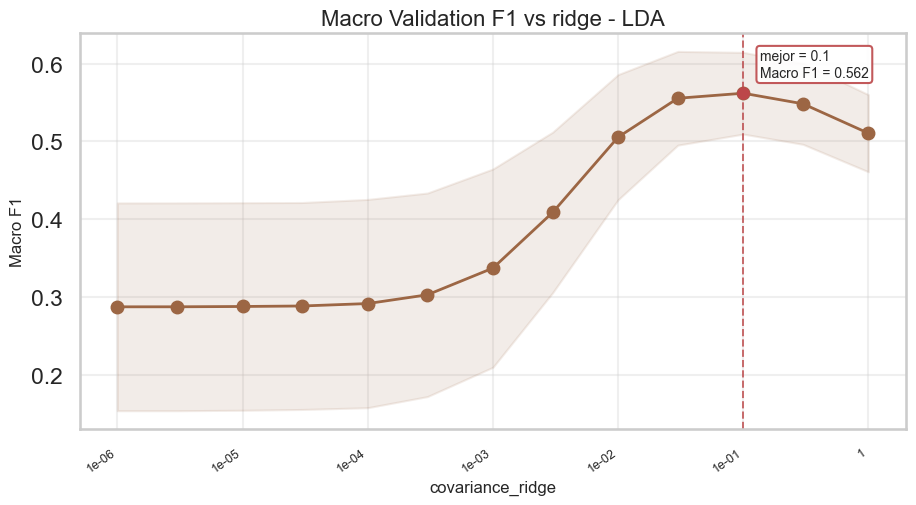

In [29]:
graficar_ajuste_ridge_lda(
    ajuste_lda_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'lda_ridge_tuning.png',
)
plt.show()


### Lectura del grafico

`LDA` necesita algo de `ridge` para estabilizar la covarianza. Con muy poca regularizacion pierde rendimiento, y con demasiada borra estructura util. El mejor tramo aparece en una zona intermedia.


### Grafico 18 - `lambda` de la logistica multiclase

La logistica multiclase repite la idea del punto 2: `lambda` chico deja un modelo mas flexible y `lambda` grande achica demasiado los coeficientes. La curva de `macro F1` ayuda a elegir el equilibrio.


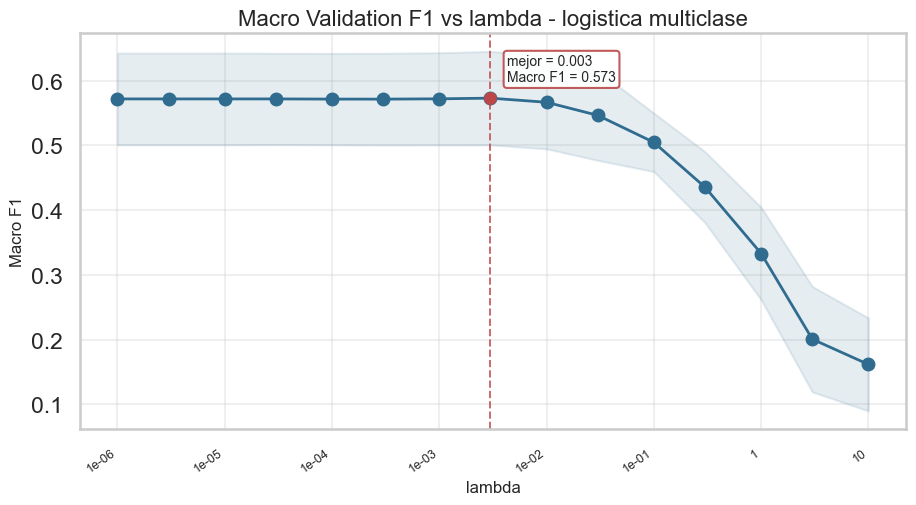

In [30]:
graficar_ajuste_lambda_multiclase(
    ajuste_logistica_multiclase_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'multiclass_logistic_lambda_tuning.png',
)
plt.show()


### Lectura del grafico

La logistica multiclase tiene un maximo claro. Con `lambda` chico se vuelve mas flexible; con `lambda` grande pierde separacion entre clases. La zona cercana al mejor valor no parece un pico aislado.


### Grafico 19 - Tuning del Random Forest

En lugar de probar un unico bosque, comparamos varias configuraciones para ver como afectan la profundidad, la cantidad de arboles, el tamano minimo de hoja y la cantidad de features usadas en cada split.


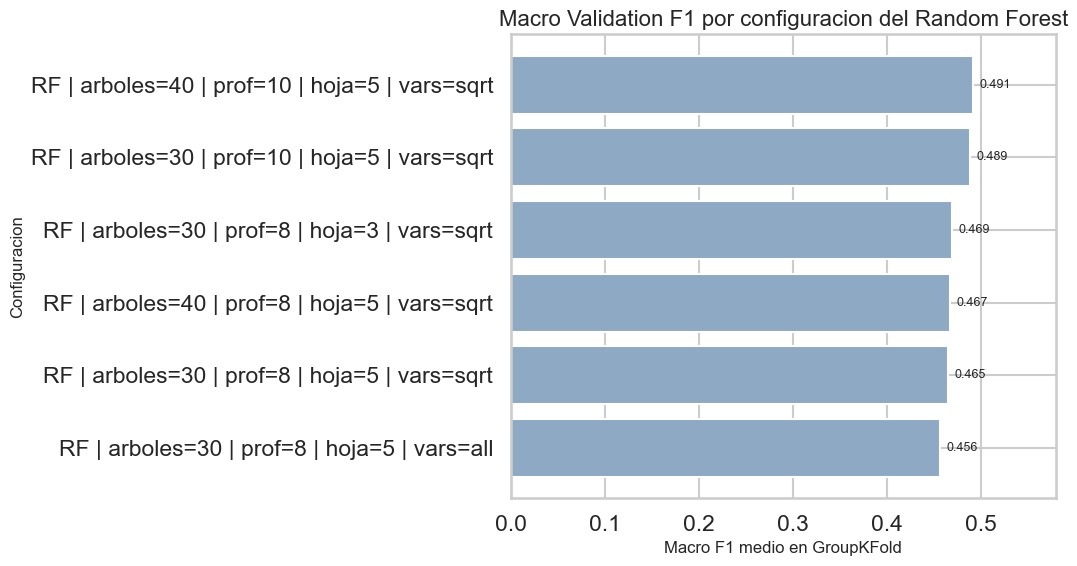

In [31]:
graficar_ajuste_random_forest(
    ajuste_rf_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'random_forest_tuning.png',
)
plt.show()


### Lectura del grafico

En `Random Forest` no alcanza con subir arboles o profundidad sin mirar el resto. Las mejores configuraciones son intermedias: tienen flexibilidad, pero no dejan que cada arbol se ajuste demasiado a este set.


### Evaluacion final out-of-fold de los tres modelos

Con las mejores configuraciones, ahora genero `out-of-fold` predictions para comparar los tres modelos en un mismo nivel.


In [32]:
resultados_punto3 = evaluar_punto3(
    desarrollo,
    folds_group_multiclase,
    mejor_config_lda,
    mejor_config_logistica_multiclase,
    mejor_config_rf,
)

evaluacion_lda = resultados_punto3['evaluacion_lda']
evaluacion_logistica_multiclase = resultados_punto3['evaluacion_logistica_multiclase']
evaluacion_rf = resultados_punto3['evaluacion_rf']
resumen_modelos_tabla = resultados_punto3['resumen_modelos_df']
metricas_por_clase_tabla = resultados_punto3['metricas_por_clase_df']
importancia_features_rf_tabla = resultados_punto3['importancia_features_rf_df']
curvas_modelos = resultados_punto3['curvas_modelos']

display(resultados_punto3['tabla_resumen_modelos_df'])
display(resultados_punto3['tabla_metricas_por_clase_df'])


,modelo,accuracy_global,macro_accuracy,macro_precision,macro_recall,macro_f1,macro_roc_auc,macro_pr_auc
0,LDA,0.633,0.817,0.635,0.588,0.596,0.869,0.639
1,Logistica multiclase,0.643,0.822,0.617,0.612,0.613,0.875,0.650
2,Random Forest,0.576,0.788,0.593,0.510,0.508,0.833,0.583


,modelo,clase,soporte,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,LDA,Insuficiente,818,0.878,0.737,0.380,0.502,0.923,0.667
1,LDA,Regular,1136,0.763,0.478,0.590,0.528,0.817,0.472
2,LDA,Bueno,1329,0.746,0.516,0.521,0.519,0.785,0.504
3,LDA,Excelente,1775,0.880,0.809,0.862,0.835,0.952,0.914
4,Logistica multiclase,Insuficiente,818,0.883,0.650,0.597,0.622,0.929,0.691
5,Logistica multiclase,Regular,1136,0.779,0.509,0.487,0.498,0.826,0.489
6,Logistica multiclase,Bueno,1329,0.749,0.525,0.476,0.500,0.792,0.505
7,Logistica multiclase,Excelente,1775,0.875,0.784,0.890,0.834,0.953,0.917
8,Random Forest,Insuficiente,818,0.860,0.759,0.197,0.313,0.900,0.620
9,Random Forest,Regular,1136,0.729,0.408,0.458,0.431,0.777,0.409


### Como leer las metricas multiclase

La primera tabla resume cada modelo. La segunda baja al detalle one-vs-all por clase, que es lo que pide la consigna para comparar `accuracy`, `precision`, `recall`, `F1`, `ROC-AUC` y `PR-AUC`.


### Grafico 20 - Comparacion global de metricas multiclase

Aca junto la comparacion entre modelos usando `accuracy` global y promedios macro de `precision`, `recall`, `F1`, `ROC-AUC` y `PR-AUC`. Quiero ver si un modelo gana de manera pareja o si depende de la metrica.


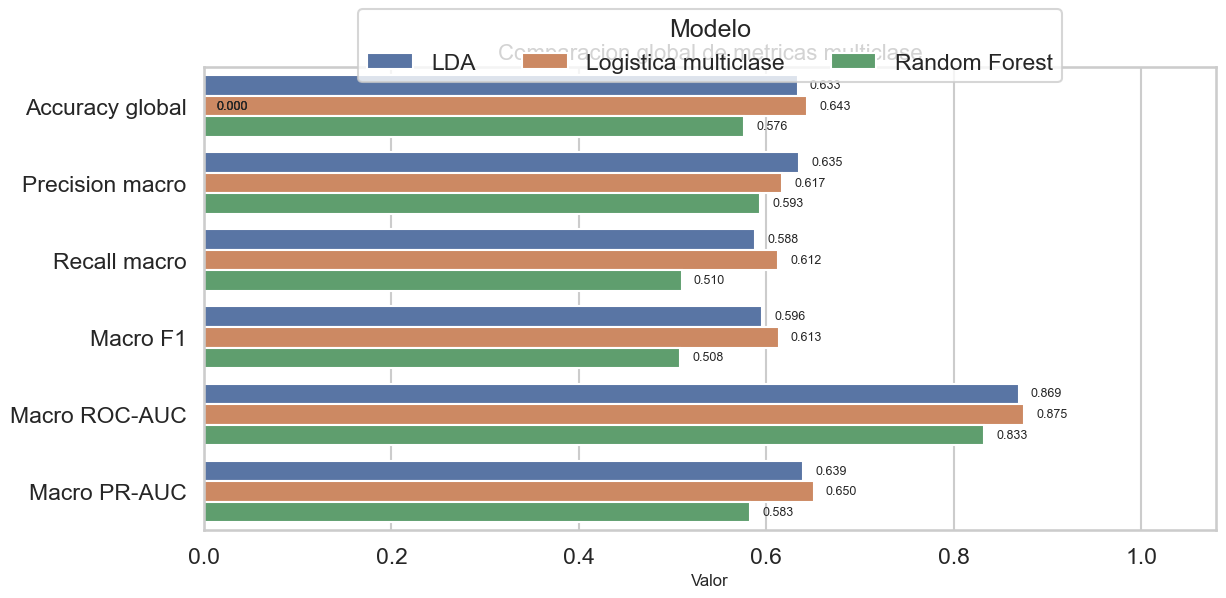

In [33]:
graficar_comparacion_metricas_modelos_multiclase(
    resumen_modelos_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'multiclass_model_metric_comparison.png',
)
plt.show()


### Lectura del grafico

La logistica multiclase sale arriba en la mayoria de las metricas globales y macro. `LDA` no queda lejos, lo que indica que la parte lineal captura bastante informacion. `Random Forest` pierde mas con validation by school.


### Grafico 21 - Matrices de confusion multiclase

Estas matrices sirven para bajar la comparacion a errores concretos de clasificacion. Aca se ve rapido entre que clases se concentra la confusion y si algun modelo comete errores mas desordenados que otro.


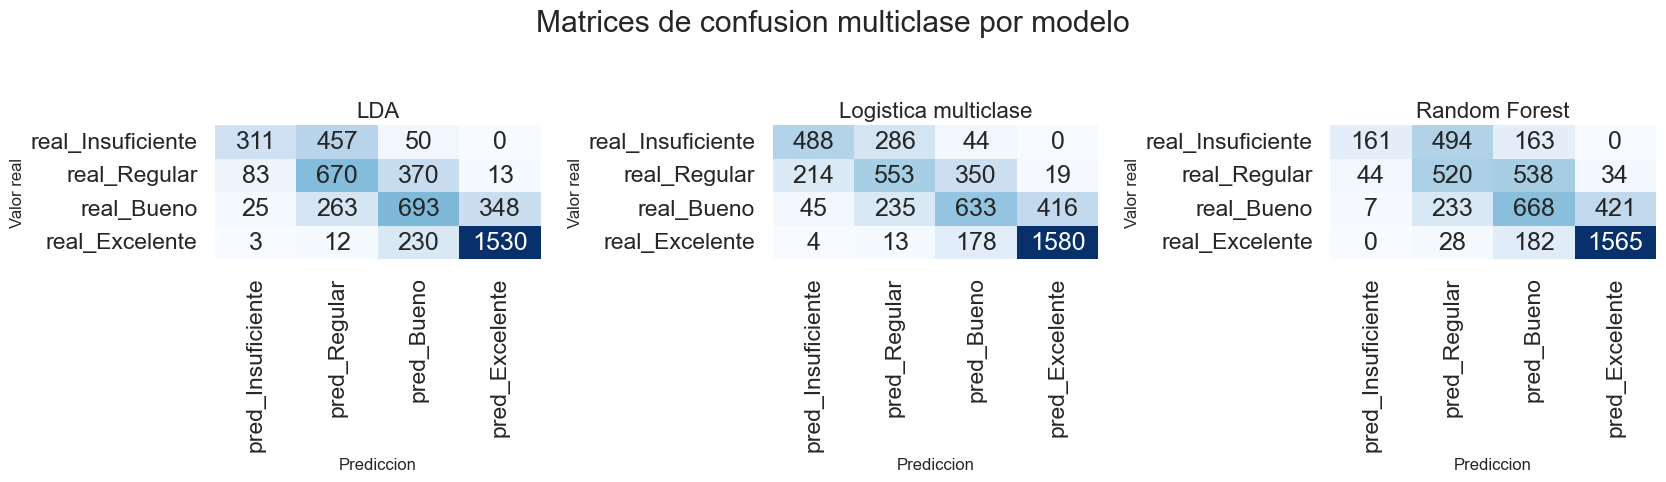

In [34]:
graficar_triplete_confusion_multiclase(
    [
        {'df': evaluacion_lda['confusion_matrix'], 'label': 'LDA'},
        {'df': evaluacion_logistica_multiclase['confusion_matrix'], 'label': 'Logistica multiclase'},
        {'df': evaluacion_rf['confusion_matrix'], 'label': 'Random Forest'},
    ],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'multiclass_confusion_triptych.png',
)
plt.show()


### Lectura del grafico

`Insuficiente` y `Excelente` son las clases mas faciles de separar. La mayoria de los errores cae entre `Regular` y `Bueno`, que son categorias vecinas. La logistica deja una diagonal mas limpia, sobre todo en esas clases intermedias.


### Grafico 22 - Metricas one-vs-all por clase en panel 2x2

En lugar de mirar `F1`, `accuracy`, `precision` y `recall` por separado, aca los juntamos en una misma salida para comparar mas rapido como cambia cada modelo segun la metrica y la clase.


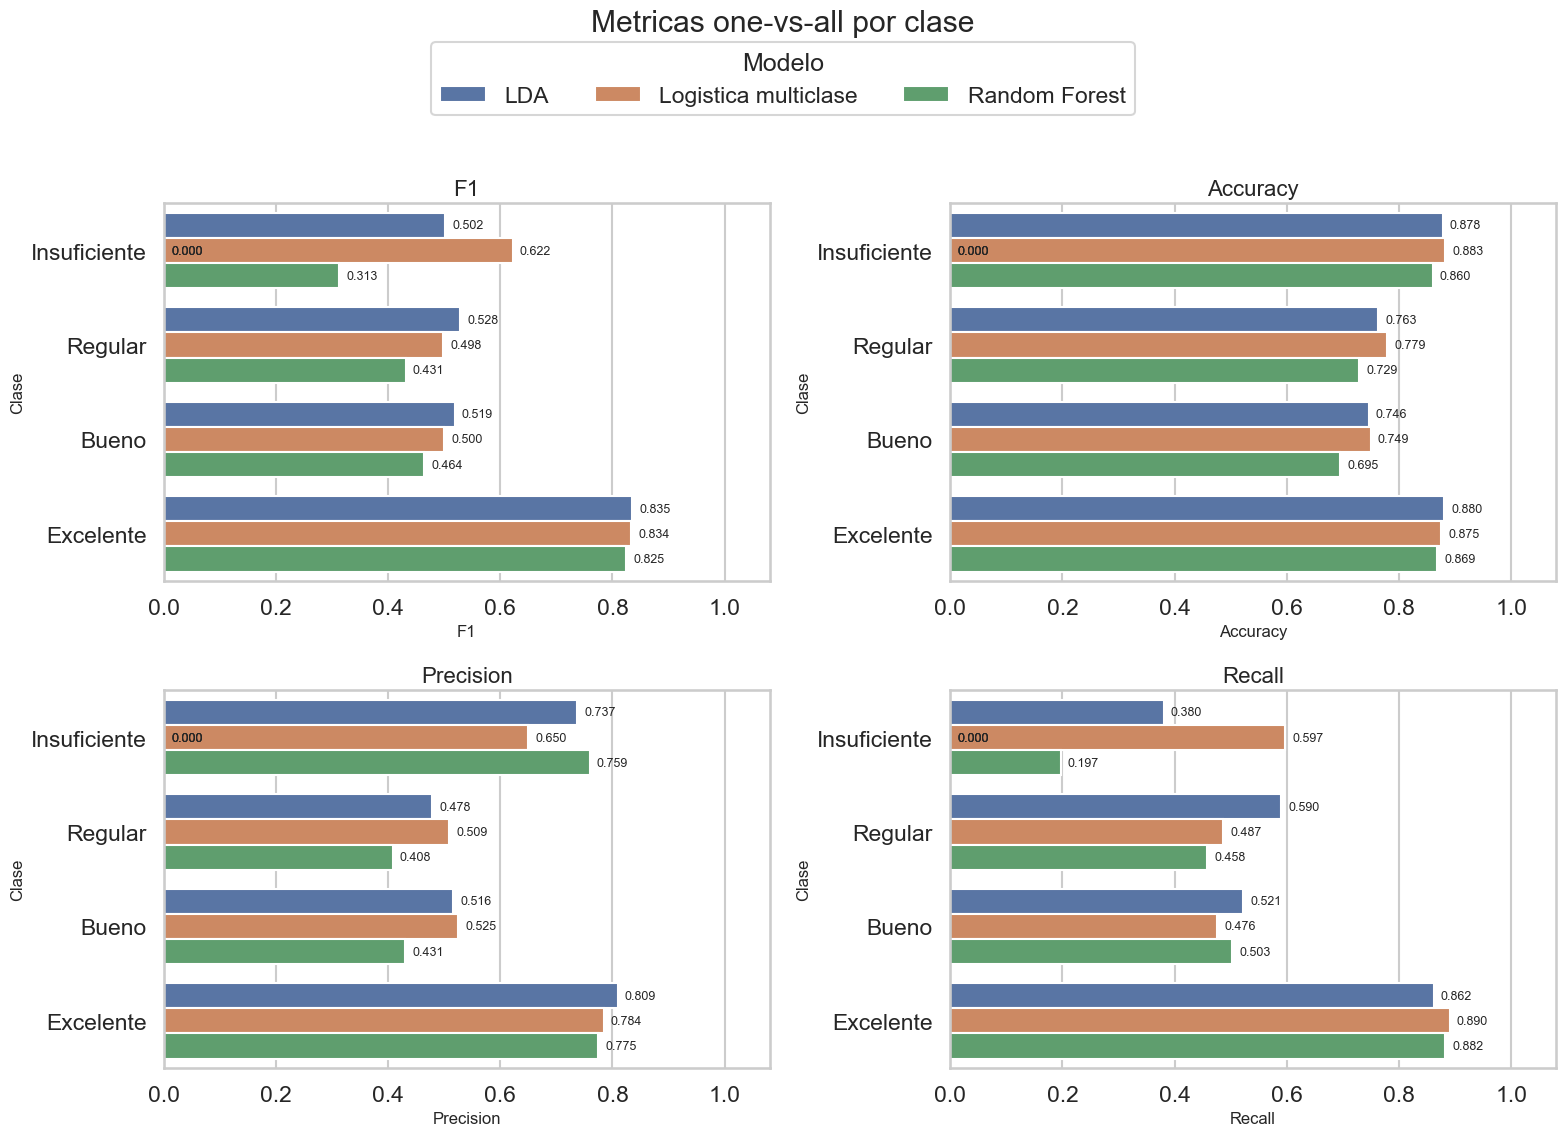

In [35]:
graficar_panel_metricas_clase_multiclase(
    metricas_por_clase_tabla,
    metricas=['f1_score', 'accuracy', 'precision', 'recall'],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'multiclass_class_metrics_panel.png',
)
plt.show()


### Lectura del grafico

El panel por clase confirma que el promedio no cuenta toda la historia. `Regular` y `Bueno` son las clases mas complicadas, mientras que las puntas se separan mejor. La logistica mantiene mejor el equilibrio entre `precision` y `recall`.


### Grafico 23 - Curvas ROC one-vs-all

Para cada clase armamos una curva ROC contra el resto y comparamos los tres modelos en el mismo subplot. Eso permite ver si la ventaja de un modelo es pareja o si cambia mucho segun la clase analizada.


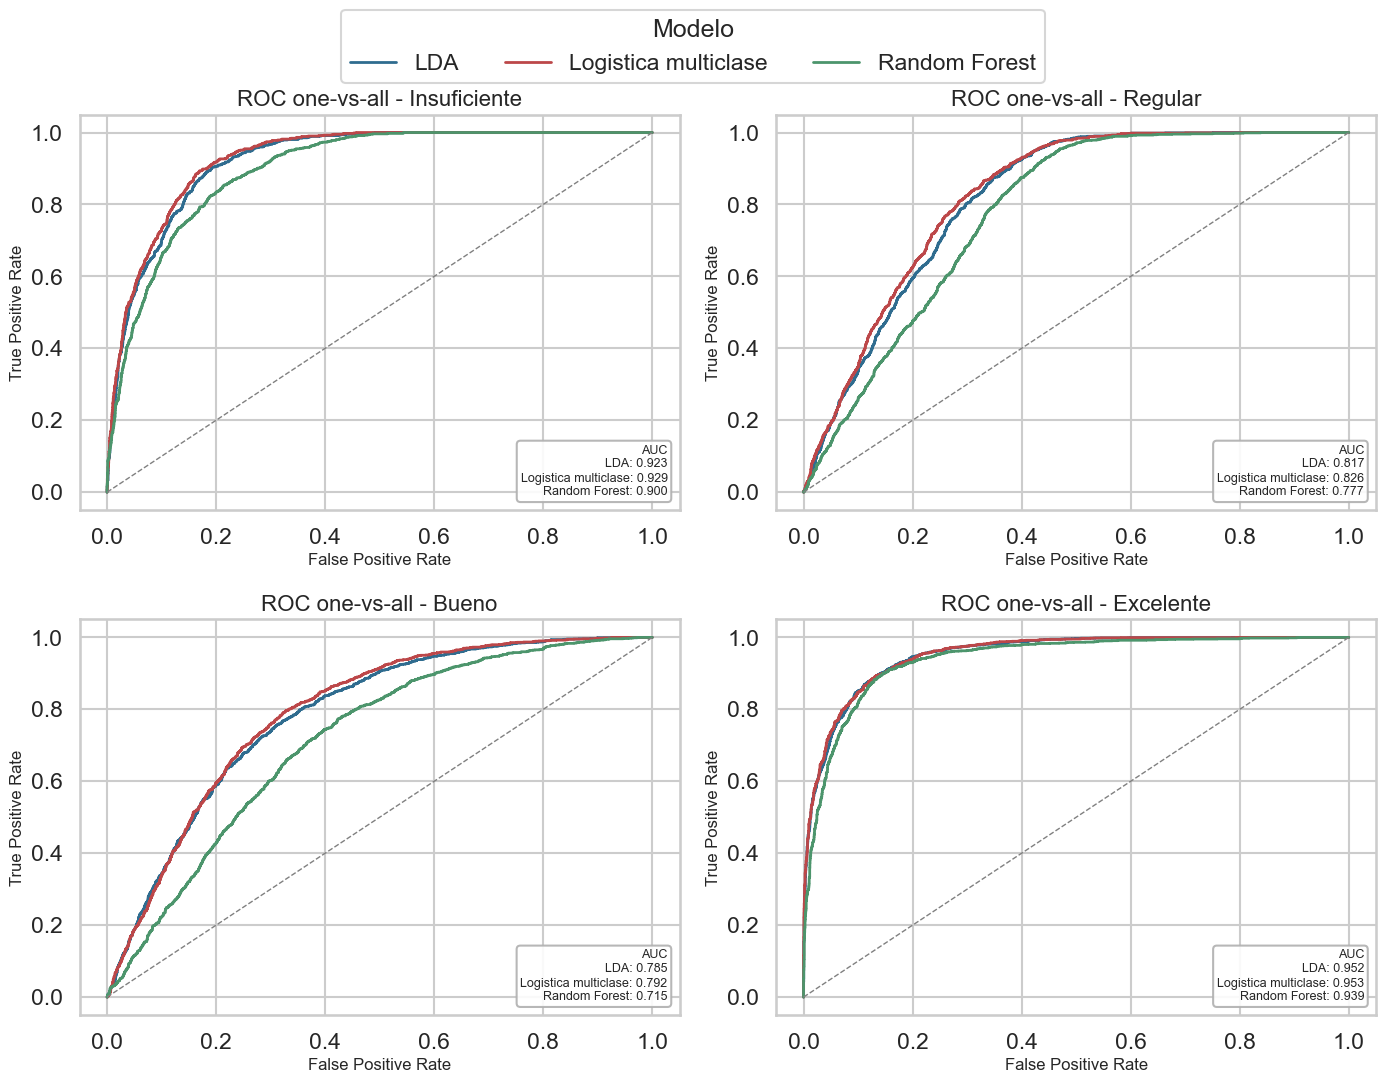

In [36]:
graficar_panel_roc_one_vs_all(
    curvas_modelos,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'multiclass_roc_one_vs_all_panel.png',
)
plt.show()


### Lectura del grafico

Las ROC one-vs-all vuelven a marcar que `Insuficiente` y `Excelente` son las clases con mejor separacion. En `Regular` y `Bueno` las curvas bajan y los modelos se acercan entre si.


### Grafico 24 - Curvas Precision-Recall one-vs-all

La curva PR es especialmente util cuando una clase no es tan frecuente o cuando queremos entender mejor cuanto cae la `precision` al intentar sostener `recall` alto.


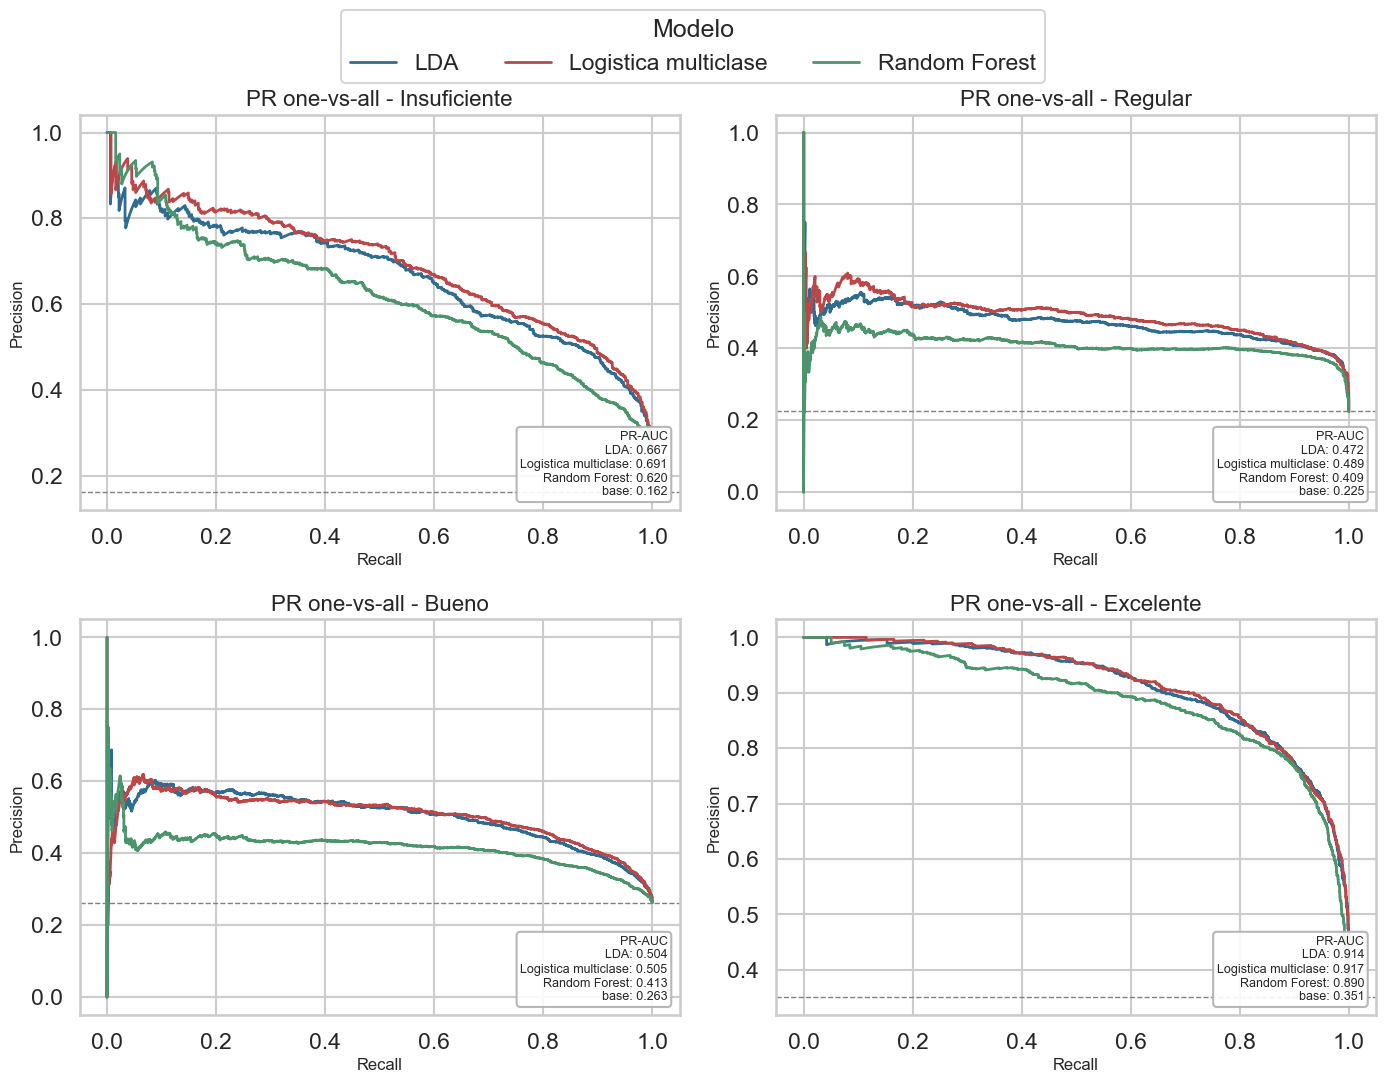

In [37]:
graficar_panel_pr_one_vs_all(
    curvas_modelos,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'multiclass_pr_one_vs_all_panel.png',
)
plt.show()


### Lectura del grafico

Las PR son mas exigentes y muestran mejor las diferencias en las clases dificiles. La logistica no gana por mucho en todos los paneles, pero sostiene mejor el equilibrio cuando sube el `recall`.


### Grafico 25 - Importancia de features del Random Forest

Aunque `Random Forest` no haya sido el mejor modelo global, este grafico sirve para ver que features usa mas para separar clases. Tambien permite comparar si el bosque captura senales parecidas a las del EDA.


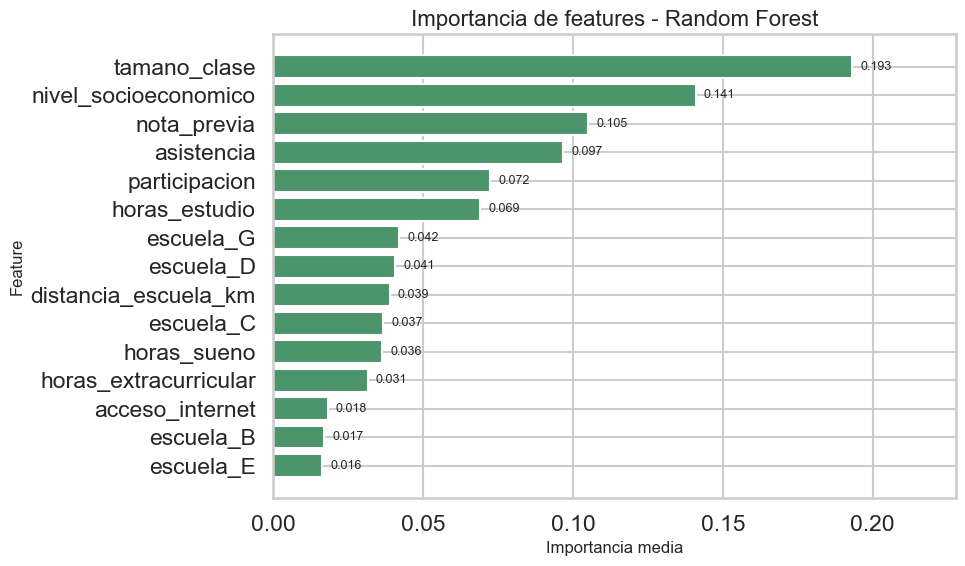

In [38]:
graficar_principales_importancias_features(
    importancia_features_rf_tabla,
    etiqueta_modelo='Random Forest',
    cantidad_principales=15,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_3 / 'random_forest_feature_importance_top15.png',
)
plt.show()


### Lectura del grafico

Las importancias del bosque coinciden con varias senales previas: pesan `nota_previa`, `asistencia`, `tamano_clase`, `nivel_socioeconomico` y dummies de `escuela`. Que `escuela` aparezca arriba ayuda a entender por que usar Group splits cambia tanto el resultado.


### Conclusion del punto 3

Con `GroupKFold` por escuela, la mejor opcion general es la logistica multiclase. `LDA` compite bien, pero la logistica sostiene mejor las metricas globales y macro.


## Punto 4 - Manejo de desbalance de clases

Vuelvo al objetivo binario y comparo rebalancing methods usando `GroupKFold` por escuela. La pregunta es si conviene intervenir el entrenamiento para detectar mejor la clase minoritaria.


En este punto comparo `no rebalancing`, `undersampling`, `oversampling` por duplicacion, `SMOTE` y `cost re-weighting`, primero en el balance del entrenamiento y despues en las metricas finales.


### Como se evalua esta parte

Cada `rebalancing method` se aplica solo al entrenamiento de cada fold. El validation set queda sin tocar, asi la comparacion mide generalizacion y no un balance fabricado en validation.


In [39]:
preparacion_punto4 = preparar_punto4(desarrollo)
folds_group_punto4 = preparacion_punto4['folds_group_punto4']


### Rebalancing methods

Comparo cinco alternativas:

- `No rebalancing`: deja la distribucion original como base.
- `Undersampling`: recorta la clase mayoritaria.
- `Oversampling duplicado`: repite casos minoritarios.
- `SMOTE`: genera casos sinteticos entre vecinos minoritarios.
- `Cost re-weighting`: mantiene las filas, pero pesa mas los errores de la clase minoritaria.

El rebalancing se aplica solo dentro del entrenamiento de cada fold.


In [40]:
rebalancing_methods_punto4 = preparacion_punto4['rebalancing_methods_punto4']
ejemplo_balance_punto4_tabla = preparacion_punto4['ejemplo_balance_punto4_df']


### Grafico 26 - Efecto de cada `rebalancing method` sobre el balance del entrenamiento

Antes de medir desempeno, verifico que cada `rebalancing method` haga lo esperado sobre el entrenamiento de un fold. Asi la comparacion posterior tiene mas contexto.


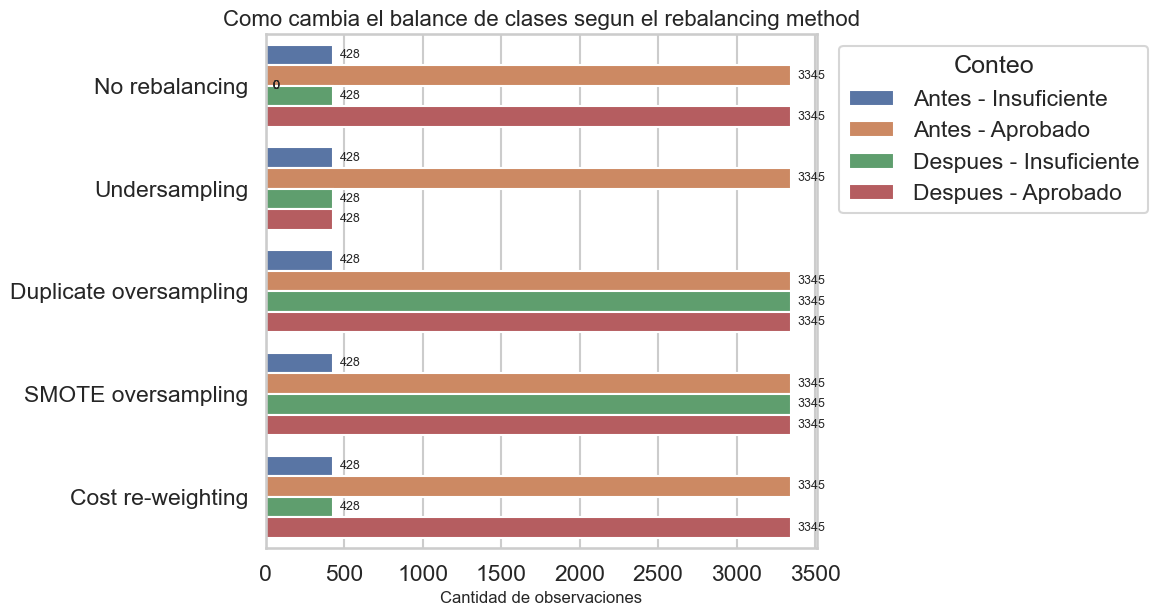

In [41]:
graficar_conteos_rebalancing_example(
    ejemplo_balance_punto4_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_4 / 'rebalancing_example_counts.png',
)
plt.show()


### Lectura del grafico

Los `rebalancing methods` intervienen de maneras distintas. `Undersampling`, duplicacion y `SMOTE` igualan conteos; `cost re-weighting` deja la base igual y cambia pesos. Dos metodos pueden verse parecidos en balance, pero no tienen el mismo costo.


### Ajuste de `lambda` por `rebalancing method`

Igual que en el punto 2, elijo `lambda` con `F1` como criterio principal. La busqueda se corre para cada `rebalancing method` porque el rebalancing cambia la muestra efectiva de entrenamiento.


In [42]:
busqueda_punto4 = ajustar_rebalancing_punto4(
    desarrollo,
    folds_group_punto4,
    rebalancing_methods_punto4,
)

ajuste_punto4_tabla = busqueda_punto4['ajuste_punto4_df']
mejor_lambda_punto4_tabla = busqueda_punto4['mejor_lambda_punto4_df']


### Grafico 27 - Validation `F1` vs `lambda` por rebalancing method

No tiene por que existir un unico `lambda` ideal para todos los `rebalancing methods`. Algunas cambian la muestra efectiva y otras cambian pesos. Miro cada curva por separado y tambien una comparacion conjunta.


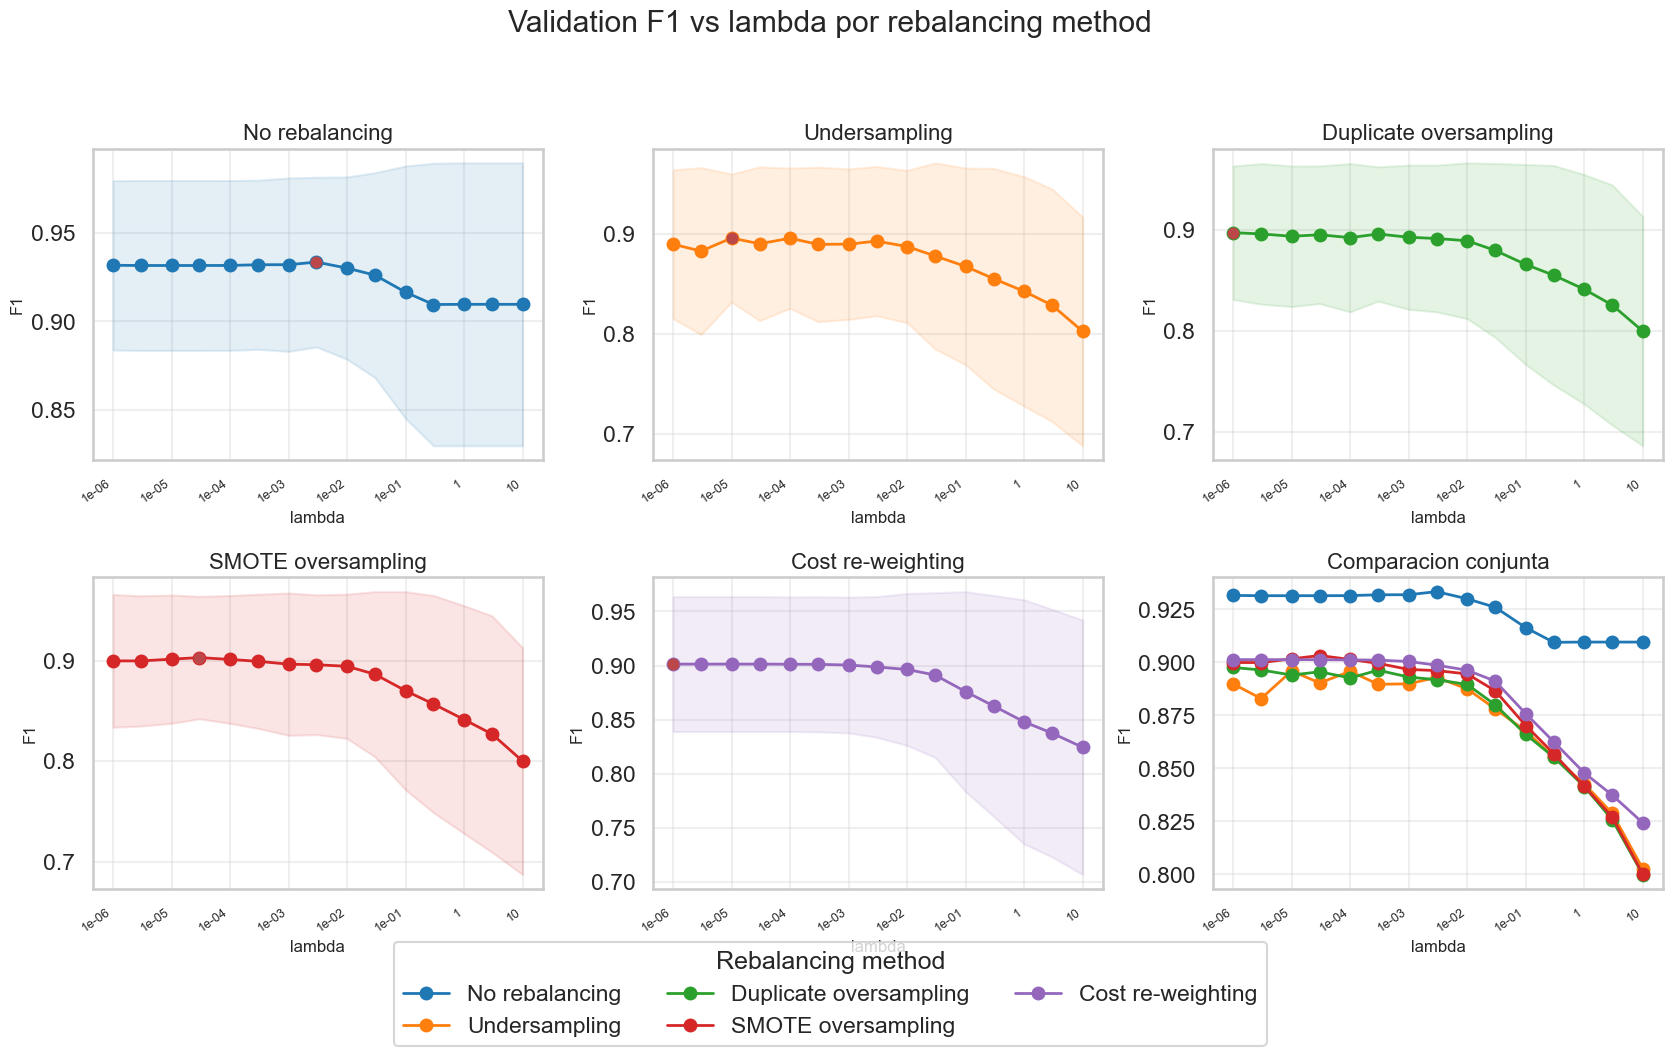

In [43]:
curvas_lambda_punto4 = armar_curvas_lambda_punto4(
    ajuste_punto4_tabla,
    rebalancing_methods_punto4,
)

graficar_panel_lambda_rebalancing_binario(
    curvas_lambda_punto4,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_4 / 'rebalancing_lambda_tuning_panel.png',
)
plt.show()


### Lectura del grafico

No conviene usar el mismo `lambda` para todos los `rebalancing methods`. Cuando cambia la muestra efectiva de entrenamiento, tambien cambia la regularizacion que necesita la logistica.


### Evaluacion final out-of-fold por `rebalancing method`

Con el mejor `lambda` de cada `rebalancing method`, ahora comparo las metricas finales sobre todo `dev` usando siempre out-of-fold predictions.


In [44]:
resultados_punto4 = evaluar_punto4(
    desarrollo,
    folds_group_punto4,
    mejor_lambda_punto4_tabla,
)

metricas_punto4_tabla = resultados_punto4['metricas_punto4_df']
matrices_punto4 = resultados_punto4['matrices_punto4']
curvas_roc_punto4 = resultados_punto4['curvas_roc_punto4']
curvas_pr_punto4 = resultados_punto4['curvas_pr_punto4']

display(resultados_punto4['tabla_metricas_punto4'])


,method,lambda,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Cost re-weighting,0.000,0.857,0.971,0.855,0.909,0.935,0.987
1,Duplicate oversampling,0.000,0.853,0.974,0.848,0.906,0.935,0.987
2,No rebalancing,0.003,0.891,0.911,0.964,0.937,0.931,0.986
3,SMOTE oversampling,0.000,0.856,0.971,0.854,0.909,0.935,0.987
4,Undersampling,0.000,0.845,0.974,0.837,0.900,0.935,0.987


### Como leer estas metricas

La tabla toma `Aprobado = 1` como clase positiva. Para entender que pasa con `Insuficiente`, conviene mirar tambien las matrices de confusion.


### Grafico 28 - Comparacion global de metricas por rebalancing method

La tabla es la referencia principal, pero esta figura permite ver rapido donde un `rebalancing method` gana o pierde: `F1`, `accuracy`, `precision`, `recall`, `ROC-AUC` y `PR-AUC`.


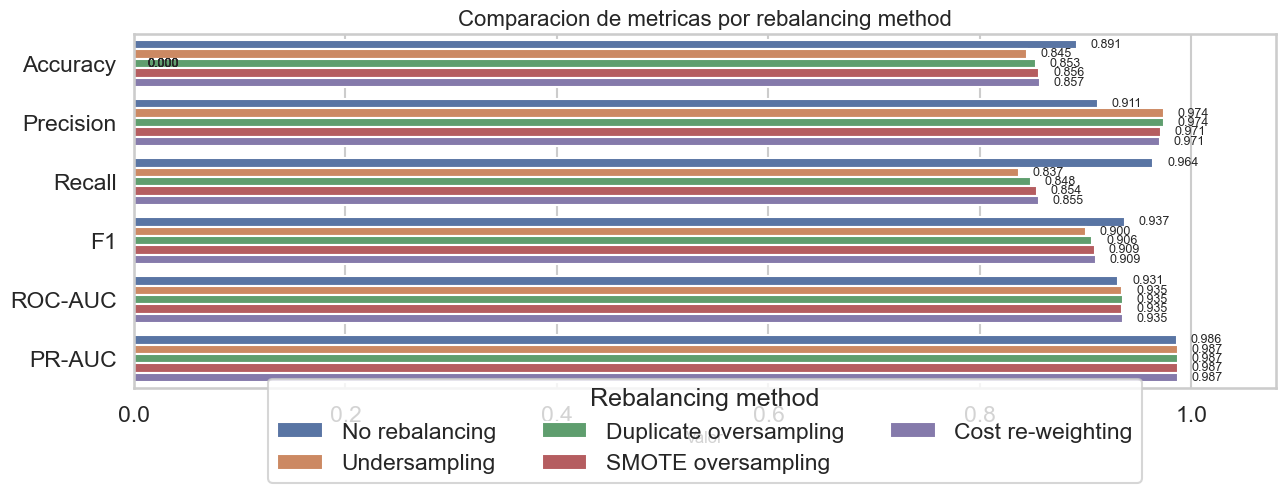

In [45]:
graficar_comparacion_metricas_rebalancing(
    metricas_punto4_tabla,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_4 / 'rebalancing_metric_comparison.png',
)
plt.show()


### Lectura del grafico

Ningun `rebalancing method` gana en todo. Las mas agresivas suben `recall`, pero pagan con menos `precision` y `accuracy`. En este problema pesa mas no dejar pasar alumnos `Insuficiente`.


### Grafico 29 - Matrices de confusion por rebalancing method

Las matrices permiten ver algo que las metricas escalares esconden: cuantos casos de la clase minoritaria se recuperan y cuantos falsos positivos aparecen sobre la mayoritaria.


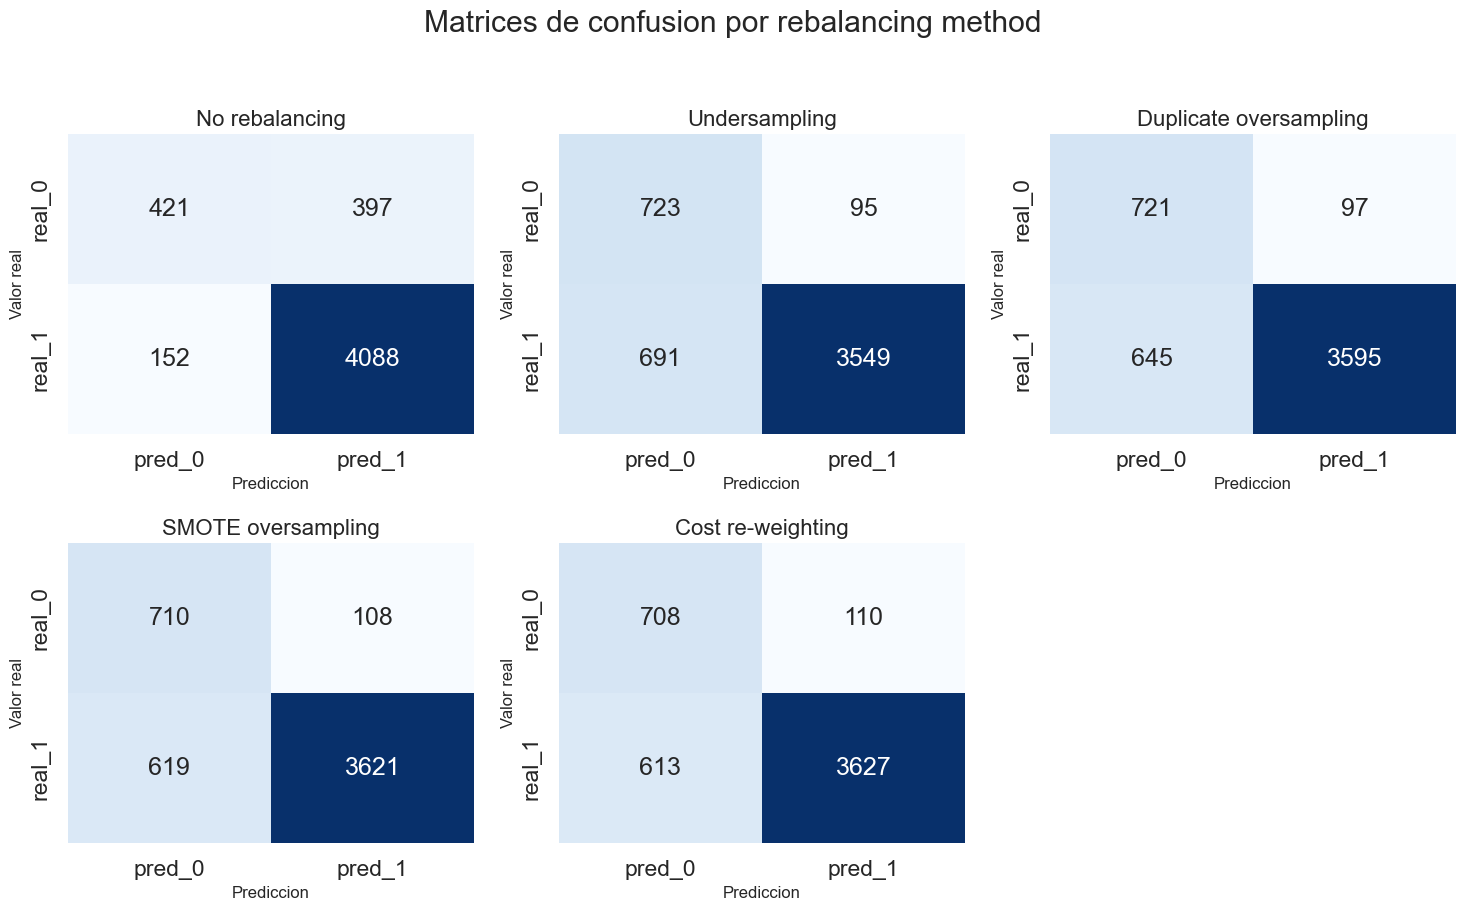

In [46]:
graficar_grilla_confusion_binaria(
    matrices_punto4,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_4 / 'rebalancing_confusion_grid.png',
)
plt.show()


### Lectura del grafico

Cuando un `rebalancing method` captura mas `Insuficiente`, tambien suele marcar mas `Aprobado` como riesgo. Los `rebalancing methods` conservadores mantienen mejor la diagonal, pero dejan pasar mas casos minoritarios.


### Grafico 30 - Curvas ROC por rebalancing method

La ROC compara separacion probabilistica sin fijar un umbral. Esto ayuda a distinguir si un `rebalancing method` ordena mejor los casos o si solo cambia la decision en `0.5`.


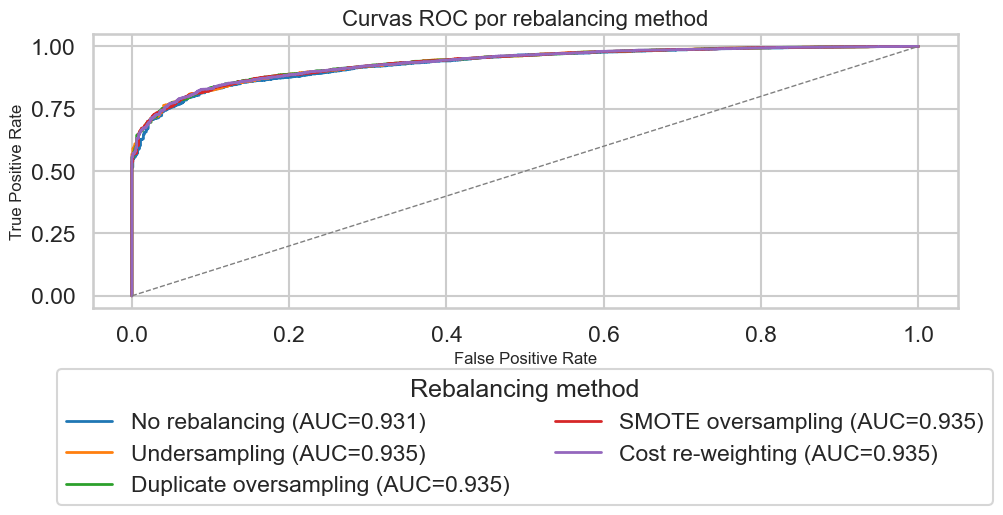

In [47]:
graficar_comparacion_roc_binaria(
    curvas_roc_punto4,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_4 / 'rebalancing_roc_comparison.png',
)
plt.show()


### Lectura del grafico

Las ROC separan dos efectos: mejor ordenamiento o cambio de umbral. En varios `rebalancing methods` la separacion general cambia poco, aunque la matriz de confusion se mueva bastante.


### Grafico 31 - Curvas Precision-Recall por rebalancing method

La curva PR es clave con clases desbalanceadas. Aca miro cuanto cae la `precision` cuando intento sostener mas `recall`.


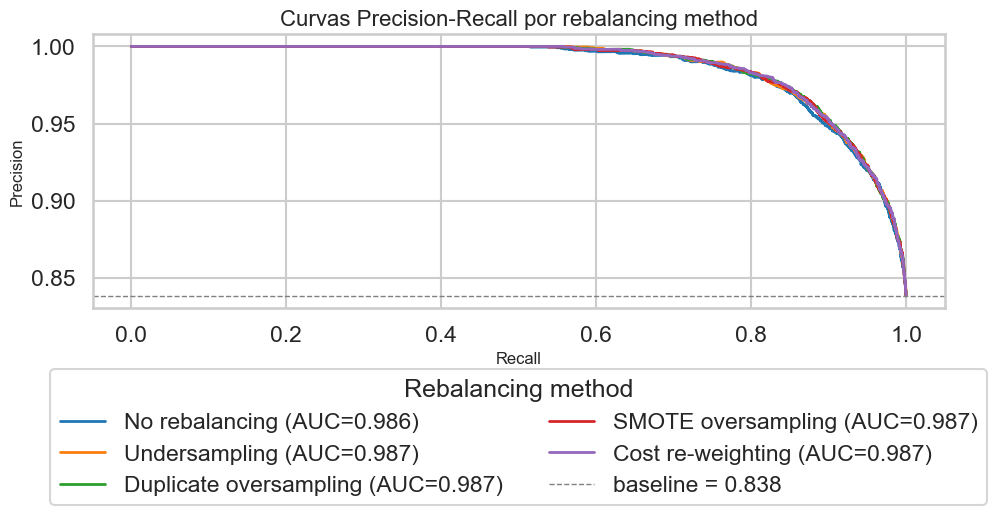

In [48]:
graficar_comparacion_pr_binaria(
    curvas_pr_punto4,
    ruta_guardado=CARPETA_FIGURAS_PUNTO_4 / 'rebalancing_pr_comparison.png',
)
plt.show()


### Lectura del grafico

En PR se ve bien el costo de buscar mas sensibilidad. Para elegir el flujo final, esta curva pesa mas que mirar `accuracy` sola.


### Conclusion del punto 4

Si miro solo metricas globales, `No rebalancing` sale muy fuerte. Pero para detectar alumnos `Insuficiente`, `cost re-weighting` es mejor opcion: recupera muchos mas casos de riesgo, aunque pierda precision.


## Punto 5 - Evaluacion final

En esta ultima parte elijo un flujo de modelado para el caso binario y otro para el multiclase, reentreno con todo `dev` y evaluo una sola vez sobre `test`.


Primero justifico la eleccion final de cada problema y despues muestro las metricas finales en `test`, junto con la estimacion de datos extra para el `Random Forest` multiclase.


In [49]:
modelos_punto5 = elegir_modelos_punto5(
    mejor_lambda_punto4_tabla,
    mejor_config_logistica_multiclase,
    mejor_config_rf,
)

eleccion_binaria_punto5 = modelos_punto5['eleccion_binaria']
eleccion_multiclase_punto5 = modelos_punto5['eleccion_multiclase']
parametros_rf_punto5 = modelos_punto5['parametros_rf']

punto5_resultados = correr_punto5(
    desarrollo,
    prueba,
    eleccion_binaria=eleccion_binaria_punto5,
    eleccion_multiclase=eleccion_multiclase_punto5,
    parametros_rf_referencia=parametros_rf_punto5,
    rf_repeats=4,
)

display(punto5_resultados['tabla_seleccion'])
display(punto5_resultados['tabla_metricas_binarias'])
display(punto5_resultados['tabla_metricas_riesgo_binario'])
display(punto5_resultados['tabla_metricas_multiclase'])
display(punto5_resultados['tabla_metricas_por_clase_multiclase'])
display(punto5_resultados['tabla_estimacion_rf'])


,problema,modelo,rebalancing,criterio_seleccion,datos_fit_final,lambda_elegido,justificacion
0,Binario,Logistica binaria L2,Cost re-weighting,Temporal split como escenario final + priorida...,todo dev,0.000,En el caso binario me interesa no dejar pasar ...
1,Multiclase,Logistica multiclase,No aplica,GroupKFold por escuela,todo dev,0.003,En el punto 3 fue el modelo que mejor combino ...


,criterio_seleccion,rebalancing,lambda,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Temporal split como escenario final + priorida...,Cost re-weighting,0.0,0.833,0.998,0.813,0.896,0.949,0.993


,criterio_seleccion,rebalancing,lambda,precision_insuficiente,recall_insuficiente,f1_insuficiente,tp_insuficiente,fp_insuficiente,fn_insuficiente
0,Temporal split como escenario final + priorida...,Cost re-weighting,0.0,0.4,0.989,0.57,88,132,1


,criterio_seleccion,accuracy_global,macro_accuracy,macro_precision,macro_recall,macro_f1,macro_roc_auc,macro_pr_auc
0,GroupKFold por escuela,0.692,0.846,0.645,0.677,0.654,0.901,0.678


,clase,soporte,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Insuficiente,89,0.901,0.538,0.787,0.639,0.948,0.668
1,Regular,164,0.814,0.555,0.494,0.523,0.862,0.537
2,Bueno,203,0.785,0.572,0.626,0.598,0.829,0.554
3,Excelente,339,0.884,0.916,0.802,0.855,0.964,0.954


,n_actual,accuracy_actual,accuracy_objetivo,intercepto_curva,pendiente_curva,metodo_ajuste,puntos_ajuste,n_inicial_ajuste,n_requerido,n_adicional,solucion_finita
0,5058,0.571,0.581,0.51,0.007,ajuste logaritmico sobre toda la curva,10,1012.0,14175.414,9118,True


### Seleccion final de flujo de modelados

Para binario elijo logistica L2 con `cost re-weighting`, porque prefiero detectar alumnos en riesgo aunque aumenten falsos positivos. Para multiclase elijo logistica multiclase: fue la opcion mas solida bajo `GroupKFold` por escuela.


### Evaluacion binaria final en test

En este panel junto la matriz de confusion, la curva ROC y la curva Precision-Recall del modelo binario elegido. Asi miro errores concretos, separacion probabilistica y efecto del desbalance en una misma salida.


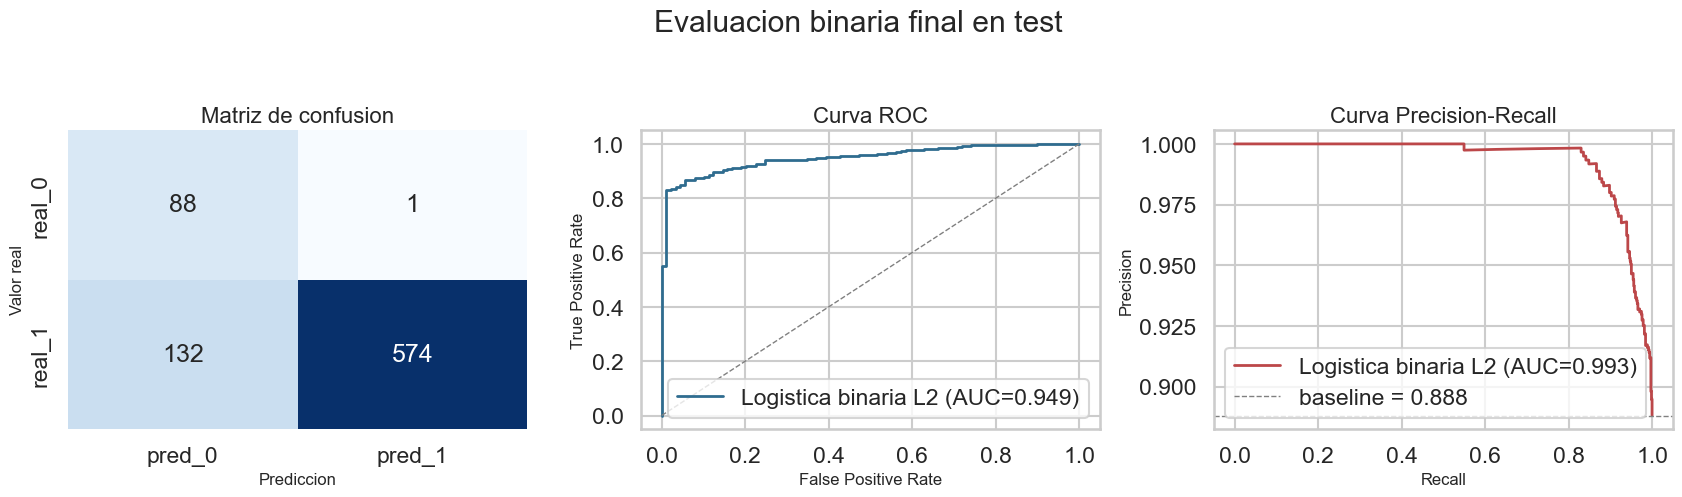

In [50]:
graficar_triplete_evaluacion_binaria(
    punto5_resultados['matriz_confusion_binaria'],
    roc_spec=punto5_resultados['curva_roc_binaria'],
    pr_spec=punto5_resultados['curva_pr_binaria'],
    title='Evaluacion binaria final en test',
    ruta_guardado=CARPETA_FIGURAS_PUNTO_5 / 'binary_test_evaluation_panel.png',
)
plt.show()


### Lectura del grafico

En `test`, el modelo binario detecta casi todos los `Insuficiente`, pero genera mas falsos positivos sobre `Aprobado`. Acepto ese costo porque el criterio elegido prioriza riesgo antes que `accuracy` global.


### Grafico 32 - Matriz de confusion multiclase en test

Esta matriz muestra como se comporta la logistica multiclase despues de reentrenar con todo `dev` y evaluar una sola vez en `test`. Sirve para ver si se repite el patron de errores visto en desarrollo.


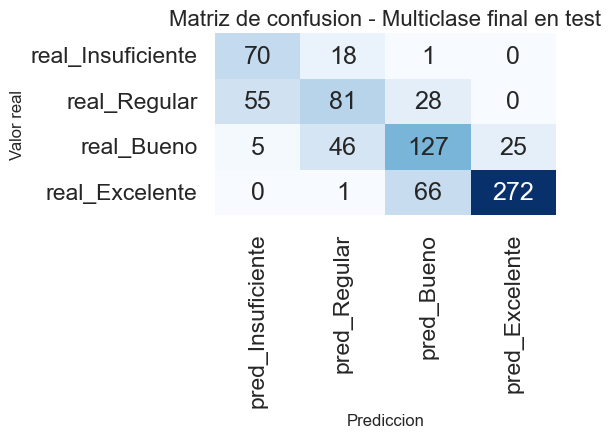

In [51]:
graficar_heatmap_matriz_confusion(
    punto5_resultados['resultado_multiclase']['confusion_matrix'],
    etiqueta_estrategia='Multiclase final en test',
    ruta_guardado=CARPETA_FIGURAS_PUNTO_5 / 'multiclass_test_confusion_matrix.png',
)
plt.show()


### Lectura del grafico

En multiclase aparece un patron parecido al de desarrollo. Las puntas (`Insuficiente` y `Excelente`) se separan mejor, y la mayor confusion queda entre `Regular` y `Bueno`. El error principal parece venir de la dificultad del problema.


### Grafico 33 - Metricas one-vs-all por clase en test

Este panel baja la evaluacion final al detalle por clase. Aca se ve si la ventaja global del modelo tambien aparece cuando miro `accuracy`, `precision`, `recall` y `F1` por separado para cada categoria.


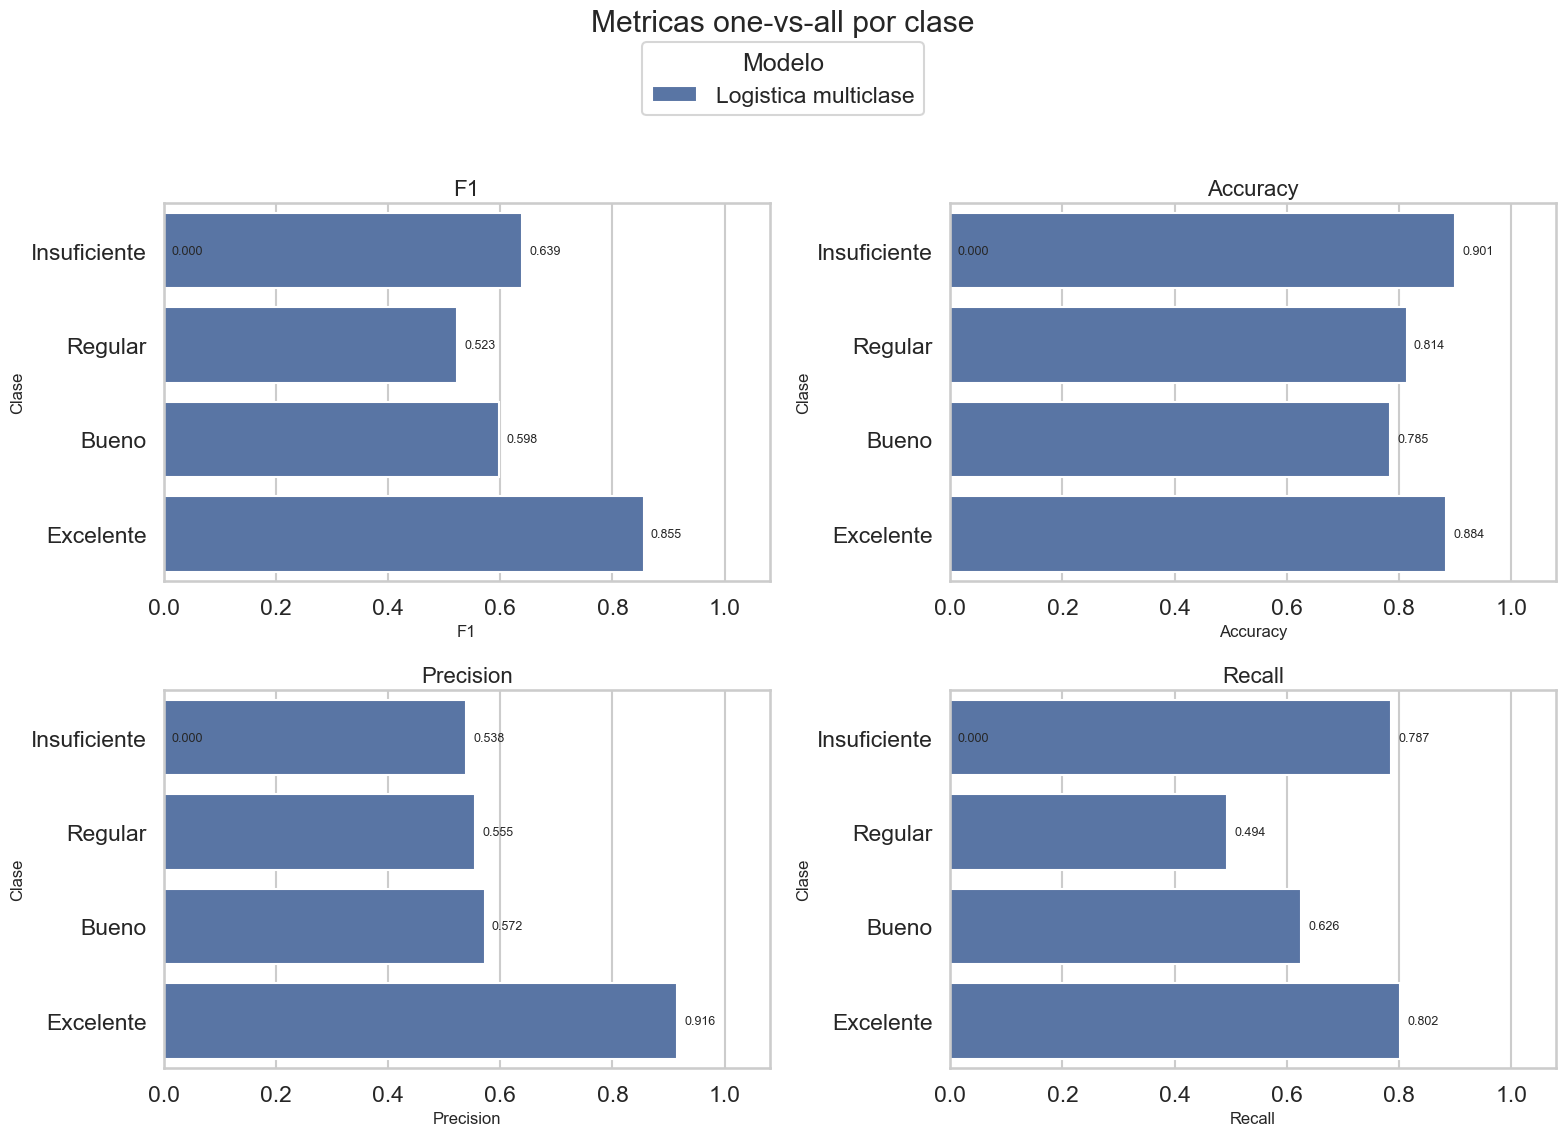

In [52]:
graficar_panel_metricas_clase_multiclase(
    punto5_resultados['resultado_multiclase']['per_class_metrics'],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_5 / 'multiclass_test_class_metrics.png',
)
plt.show()


### Lectura del grafico

El panel por clase resume la matriz anterior. `Excelente` e `Insuficiente` salen mejor, mientras que `Regular` y `Bueno` concentran la dificultad. El patron es parecido al de validation.


### Grafico 34 - Curvas ROC one-vs-all en test

Estas curvas muestran la separacion probabilistica del modelo final para cada clase contra el resto. Sirven para ver si el rendimiento es parejo o cambia mucho entre categorias.


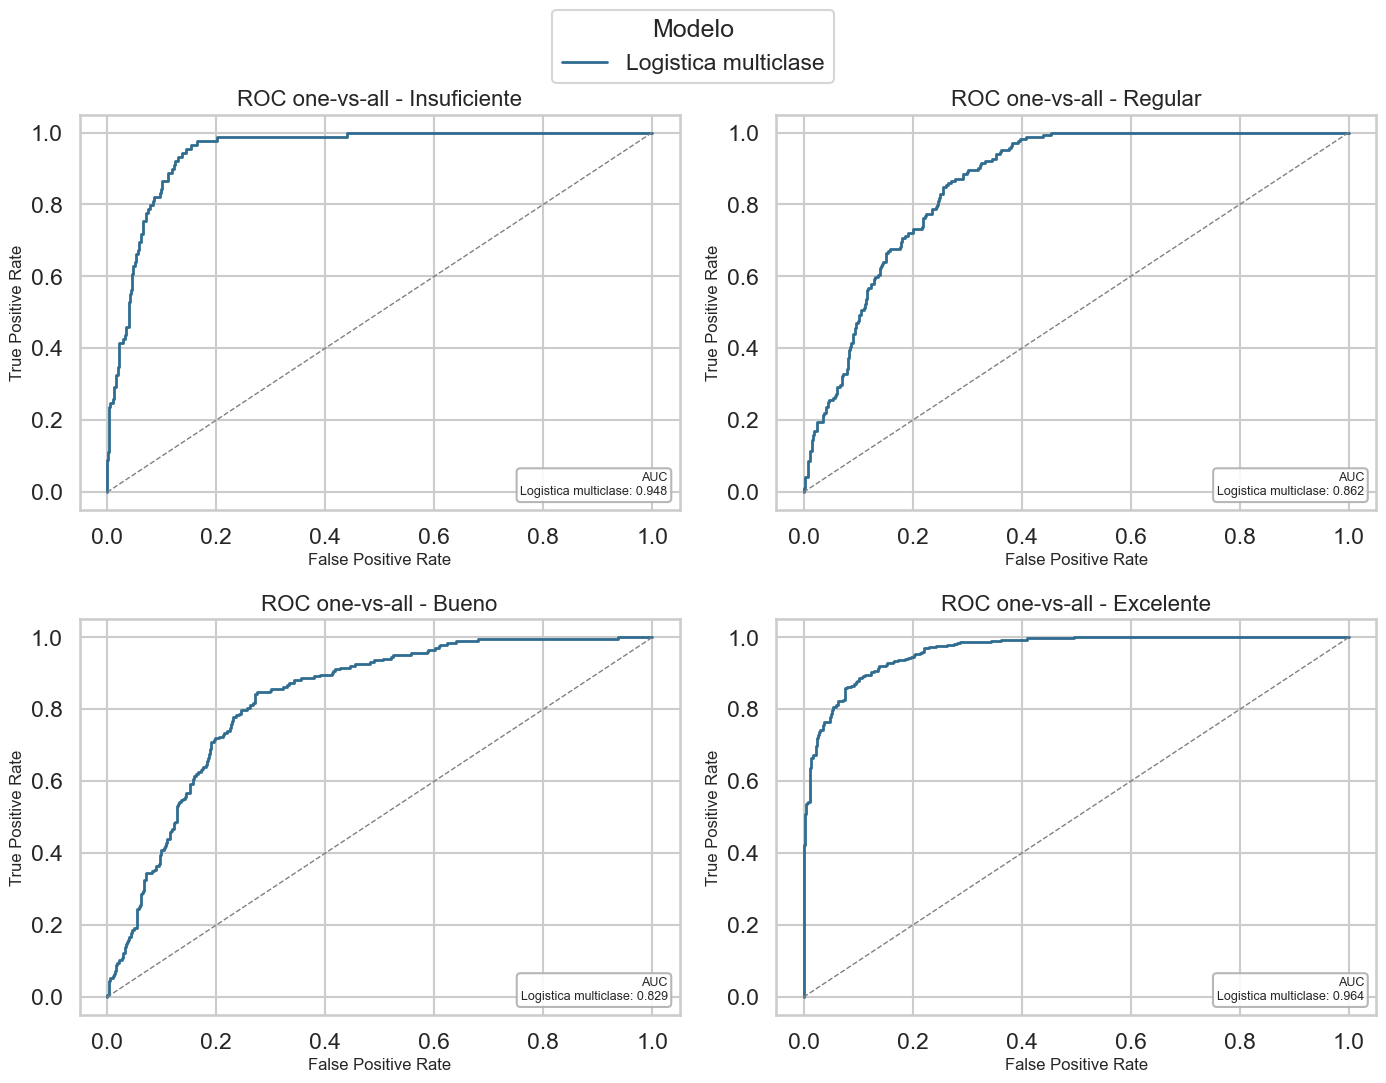

In [53]:
graficar_panel_roc_one_vs_all(
    punto5_resultados['curvas_multiclase'],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_5 / 'multiclass_test_roc_panel.png',
)
plt.show()


### Lectura del grafico

Las ROC por clase muestran buena separacion general, sobre todo en `Excelente` e `Insuficiente`. Las clases del medio son mas dificiles, igual que en las matrices y metricas one-vs-all.


### Grafico 35 - Curvas Precision-Recall one-vs-all en test

La comparacion PR completa la lectura anterior con una metrica mas exigente. Aca interesa especialmente ver como cambia la `precision` cuando intento sostener `recall` alto para cada clase.


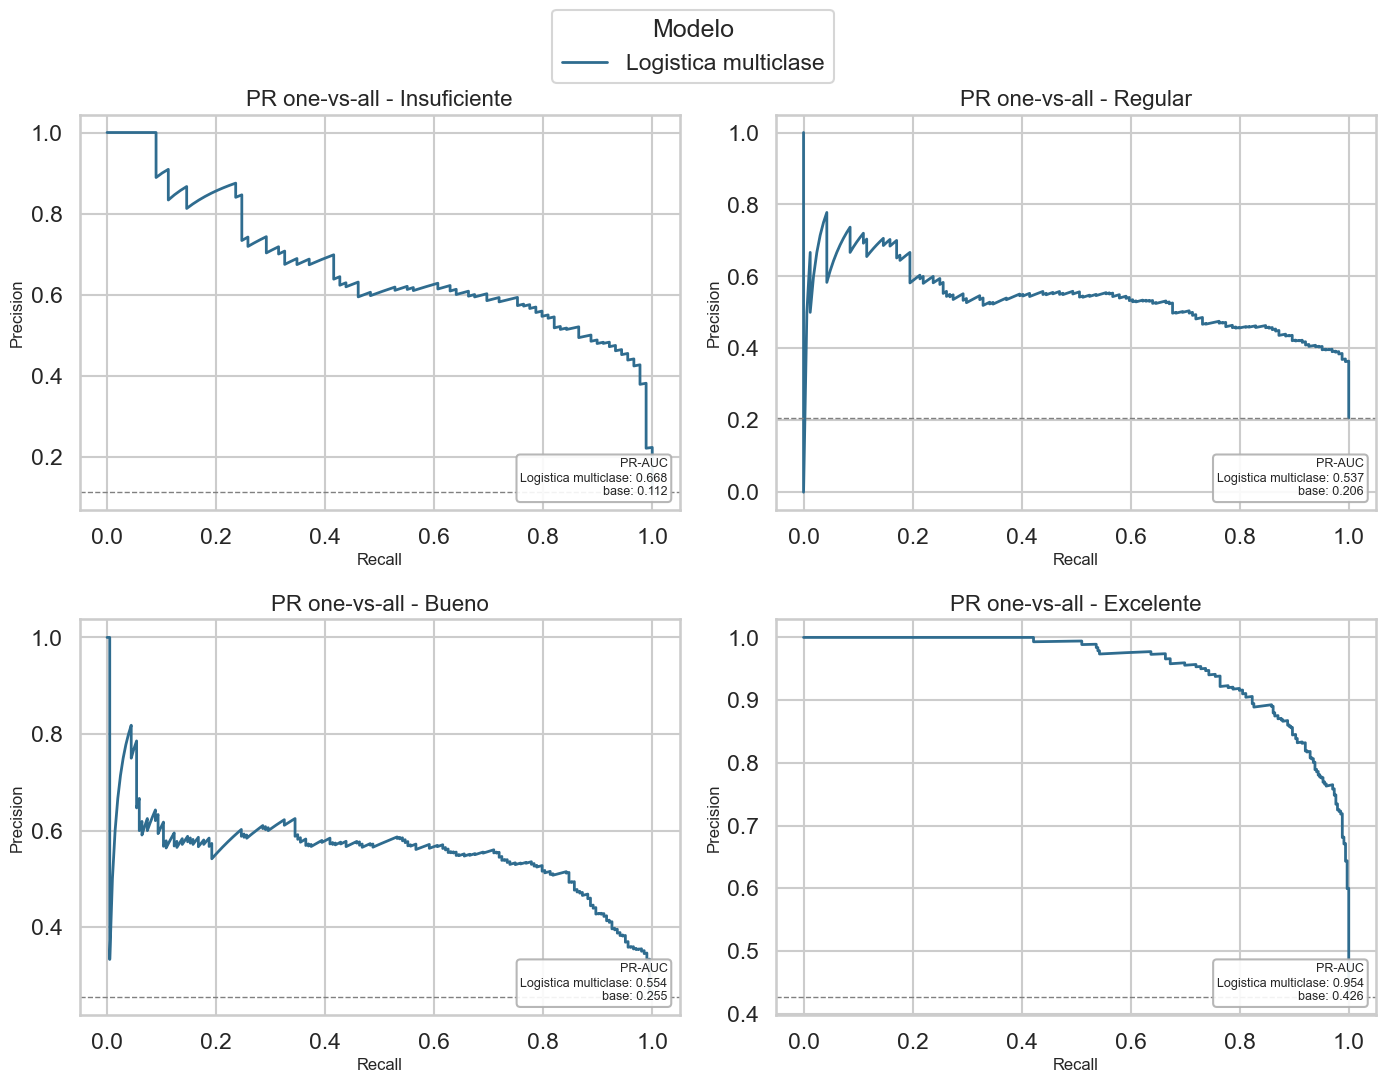

In [54]:
graficar_panel_pr_one_vs_all(
    punto5_resultados['curvas_multiclase'],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_5 / 'multiclass_test_pr_panel.png',
)
plt.show()


### Lectura del grafico

Las PR repiten la misma historia con una metrica mas dura. `Excelente` vuelve a destacarse y las clases del medio quedan mas ajustadas cuando intento sostener `recall`.


### Grafico 36 - Curva de aprendizaje del Random Forest multiclase

Aunque el modelo final multiclase no sea `Random Forest`, esta curva responde el inciso 5.3. La uso para estimar cuantos datos extra harian falta para ganar alrededor de `1%` de `accuracy`.


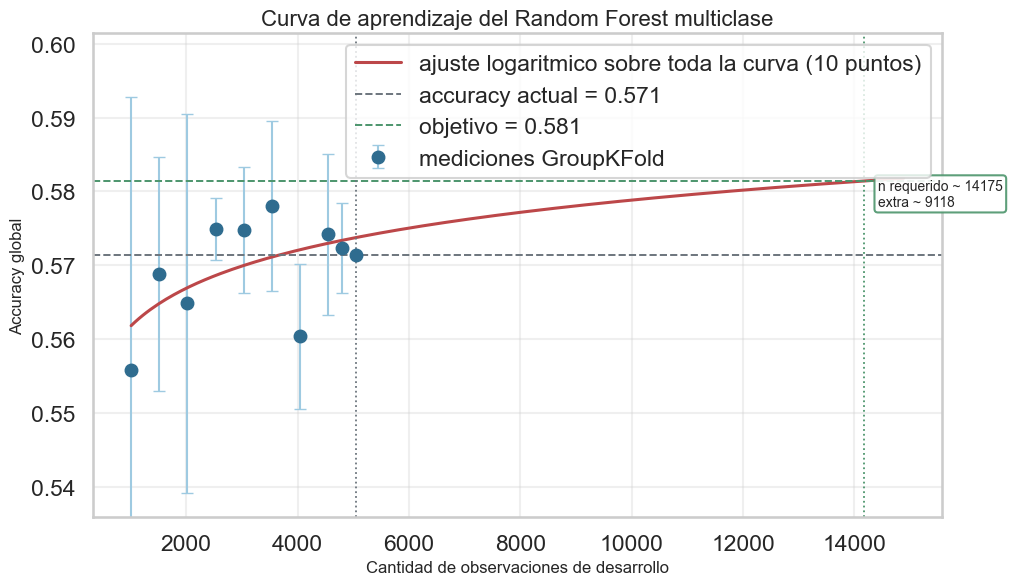

In [55]:
graficar_estimacion_curva_aprendizaje_rf(
    punto5_resultados['resultados_curva_rf']['curve_summary_df'],
    punto5_resultados['resultados_curva_rf']['fitted_curve_df'],
    punto5_resultados['resultados_curva_rf']['estimate_df'],
    ruta_guardado=CARPETA_FIGURAS_PUNTO_5 / 'rf_learning_curve_estimate.png',
)
plt.show()


### Lectura del grafico

La curva sube cada vez mas lento. El ajuste logaritmico resume esa idea de rendimientos decrecientes: mejorar otro punto de `accuracy` parece requerir muchos datos. Lo tomo como aproximacion, no como numero exacto.


### Conclusion del punto 5

Para el caso binario, la logistica L2 con `cost re-weighting` es la eleccion que mejor acompaña el objetivo de detectar riesgo. En `test` encuentra `88` de los `89` casos `Insuficiente`, aunque paga con mas falsos positivos.

En multiclase, la logistica multiclase sigue siendo la opcion mas estable bajo `GroupKFold` por escuela. Para el `Random Forest`, la curva de aprendizaje estima que harian falta aproximadamente `9.118` datos nuevos para ganar cerca de `1%` de `accuracy`.
